# Data Collection and Analysis / Сбор и анализ данных.

Исследование географических различий в заболеваемости аутоиммунными, иммуноопосредованными, онкологическими
и сердечно-сосудистыми заболеваниями.

Анализируемые факторы: экономическое развитие, возрастная структура населения и ожидаемая продолжительность жизни. Дополнительно рассматриваются возможные географические и экологические факторы.

In [1]:
import pandas as pd

In [2]:
gdp_raw = pd.read_excel('../data/raw/API_NY.GDP.PCAP.PP.KD_DS2_en_excel_v2_5411.xls',header=3)
gdp_raw.head(3)

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,36926.113069,38213.289239,39378.228411,39754.560072,30408.827090,35207.170909,39083.461640,42783.248907,45428.002728,NaN
1,Africa Eastern and Southern,AFE,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,4210.935695,4223.188050,4229.839634,4200.531044,3978.133502,4049.969513,4098.126192,4076.224898,4099.889812,4164.679177
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN


In [3]:
filtered = gdp_raw[gdp_raw['Country Code'].isna()]
filtered

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025


In [4]:
gdp_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 70 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    str    
 1   Country Code    266 non-null    str    
 2   Indicator Name  266 non-null    str    
 3   Indicator Code  266 non-null    str    
 4   1960            0 non-null      float64
 5   1961            0 non-null      float64
 6   1962            0 non-null      float64
 7   1963            0 non-null      float64
 8   1964            0 non-null      float64
 9   1965            0 non-null      float64
 10  1966            0 non-null      float64
 11  1967            0 non-null      float64
 12  1968            0 non-null      float64
 13  1969            0 non-null      float64
 14  1970            0 non-null      float64
 15  1971            0 non-null      float64
 16  1972            0 non-null      float64
 17  1973            0 non-null      float64
 18  1

In [5]:
gdp_clean = gdp_raw.copy()
gdp_clean = gdp_clean.dropna(axis=1,how='all')

In [6]:
gdp_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 40 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    str    
 1   Country Code    266 non-null    str    
 2   Indicator Name  266 non-null    str    
 3   Indicator Code  266 non-null    str    
 4   1990            233 non-null    float64
 5   1991            234 non-null    float64
 6   1992            234 non-null    float64
 7   1993            234 non-null    float64
 8   1994            235 non-null    float64
 9   1995            236 non-null    float64
 10  1996            236 non-null    float64
 11  1997            238 non-null    float64
 12  1998            238 non-null    float64
 13  1999            238 non-null    float64
 14  2000            240 non-null    float64
 15  2001            240 non-null    float64
 16  2002            241 non-null    float64
 17  2003            241 non-null    float64
 18  2

In [7]:
countries = [
    'United States',
    'Greece',
    'Georgia',
    'Italy',
    'France',
    'Japan',
    'Finland',
    'Korea, Rep.',
    'China',
    'Russian Federation',
    'Germany',
    'Qatar',
    'United Arab Emirates',
    'Kuwait',
    'Saudi Arabia',
    'Bahrain',
    'Oman']

In [8]:
gdp_clean.loc[gdp_clean['Country Name'].isin(countries),['Country Name', 'Country Code', '2024', '2025']].sort_values('Country Name')


,Country Name,Country Code,2024,2025
22,Bahrain,BHR,59060.181836,60669.630780
40,China,CHN,23841.476914,25066.521530
75,Finland,FIN,55901.320230,55735.217492
77,France,FRA,54799.348269,55124.539256
82,Georgia,GEO,24146.623411,25135.782246
55,Germany,DEU,62654.602264,62823.773665
89,Greece,GRC,37474.279824,38218.721629
116,Italy,ITA,53284.874505,53606.078957
119,Japan,JPN,47479.844855,48283.372396
126,"Korea, Rep.",KOR,55070.938619,55697.084809


In [9]:
gdp_clean = gdp_clean.rename(columns={'Country Name':'country','Country Code':'code'})
gdp_clean

,country,code,Indicator Name,Indicator Code,1990,1991,1992,1993,1994,1995,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,33146.670548,34079.230463,34458.142298,34627.743475,35580.533978,35476.409987,...,36926.113069,38213.289239,39378.228411,39754.560072,30408.827090,35207.170909,39083.461640,42783.248907,45428.002728,NaN
1,Africa Eastern and Southern,AFE,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,3520.019233,3425.136430,3252.316888,3127.877714,3099.430165,3155.044828,...,4210.935695,4223.188050,4229.839634,4200.531044,3978.133502,4049.969513,4098.126192,4076.224898,4099.889812,4164.679177
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
3,Africa Western and Central,AFW,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,4165.726363,4101.378889,4090.019417,3928.312331,3812.275413,3774.104495,...,6034.826989,6009.516114,6026.527572,6070.284769,5698.766702,5702.134886,5818.483224,5886.796636,6009.084662,6139.587294
4,Angola,AGO,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,8366.412716,8170.249394,7445.438367,5481.763868,5377.990350,5981.532576,...,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.190820
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,10434.888826,10856.290207,11188.224463,11774.117851,11137.502856,12362.421018,13022.462744,14240.203032,15716.292556,16461.294363
262,"Yemen, Rep.",YEM,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
263,South Africa,ZAF,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,10811.151533,10459.355982,10053.610121,9976.965065,10130.805823,10318.838598,...,14501.280782,14573.598084,14553.561567,14352.669871,13250.566659,13681.954814,13767.496759,13695.375569,13597.653850,13592.048402
264,Zambia,ZMB,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,2425.111287,2364.862340,2268.498122,2365.629536,2110.583256,2119.956429,...,3598.171660,3612.505977,3646.959665,3591.564189,3391.595412,3503.034914,3585.123791,3673.484197,3708.069043,3742.256463


In [10]:
gdp_clean.head(3)

,country,code,Indicator Name,Indicator Code,1990,1991,1992,1993,1994,1995,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,33146.670548,34079.230463,34458.142298,34627.743475,35580.533978,35476.409987,...,36926.113069,38213.289239,39378.228411,39754.560072,30408.827090,35207.170909,39083.461640,42783.248907,45428.002728,NaN
1,Africa Eastern and Southern,AFE,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,3520.019233,3425.136430,3252.316888,3127.877714,3099.430165,3155.044828,...,4210.935695,4223.188050,4229.839634,4200.531044,3978.133502,4049.969513,4098.126192,4076.224898,4099.889812,4164.679177
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN


In [11]:
gdp_selected = gdp_clean.loc[gdp_clean['country'].isin(countries),['country','code','2024']].rename(
    columns={'2024':'gdp_per_capita_ppp_2024'}).sort_values('country').reset_index(drop=True)
gdp_selected


,country,code,gdp_per_capita_ppp_2024
0,Bahrain,BHR,59060.181836
1,China,CHN,23841.476914
2,Finland,FIN,55901.320230
3,France,FRA,54799.348269
4,Georgia,GEO,24146.623411
5,Germany,DEU,62654.602264
6,Greece,GRC,37474.279824
7,Italy,ITA,53284.874505
8,Japan,JPN,47479.844855
9,"Korea, Rep.",KOR,55070.938619


In [12]:
gdp_clean['2024'].notna().sum()

np.int64(243)

## Список стран Всемирного банка

In [13]:
import requests

url = 'https://api.worldbank.org/v2/country?format=json&per_page=400'

response = requests.get(url)
response.raise_for_status()
response.status_code


C:\Users\Ирина\AppData\Roaming\Python\Python313\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.4.0.post2)/charset_normalizer (3.4.5) doesn't match a supported version!
  warnings.warn(


200

In [14]:
countries_data = response.json()[1]

countries_wb = pd.json_normalize(countries_data)

countries_wb.head(3)

,id,iso2Code,name,capitalCity,longitude,latitude,region.id,region.iso2code,region.value,adminregion.id,adminregion.iso2code,adminregion.value,incomeLevel.id,incomeLevel.iso2code,incomeLevel.value,lendingType.id,lendingType.iso2code,lendingType.value
0,ABW,AW,Aruba,Oranjestad,-70.0167,12.5167,LCN,ZJ,Latin America & Caribbean,,,,HIC,XD,High income,LNX,XX,Not classified
1,AFE,ZH,Africa Eastern and Southern,,,,NA,NA,Aggregates,,,,NA,NA,Aggregates,,,Aggregates
2,AFG,AF,Afghanistan,Kabul,69.1761,34.5228,MEA,ZQ,"Middle East, North Africa, Afghanistan & Pakistan",MNA,XQ,"Middle East, North Africa, Afghanistan & Pakis...",LIC,XM,Low income,IDX,XI,IDA


## Создание таблицы стран и территорий с географическими регионами и группами доходов, исключив агрегированные показатели Всемирного банка 

In [15]:
countries_clean = countries_wb[countries_wb['region.value'] != 'Aggregates'].copy()
countries_clean.shape

(217, 18)

In [16]:
countries_clean.head(3)

,id,iso2Code,name,capitalCity,longitude,latitude,region.id,region.iso2code,region.value,adminregion.id,adminregion.iso2code,adminregion.value,incomeLevel.id,incomeLevel.iso2code,incomeLevel.value,lendingType.id,lendingType.iso2code,lendingType.value
0,ABW,AW,Aruba,Oranjestad,-70.0167,12.5167,LCN,ZJ,Latin America & Caribbean,,,,HIC,XD,High income,LNX,XX,Not classified
2,AFG,AF,Afghanistan,Kabul,69.1761,34.5228,MEA,ZQ,"Middle East, North Africa, Afghanistan & Pakistan",MNA,XQ,"Middle East, North Africa, Afghanistan & Pakis...",LIC,XM,Low income,IDX,XI,IDA
5,AGO,AO,Angola,Luanda,13.242,-8.81155,SSF,ZG,Sub-Saharan Africa,SSA,ZF,Sub-Saharan Africa (excluding high income),LMC,XN,Lower middle income,IBD,XF,IBRD


In [17]:
countries_selected = countries_clean[['id','name','region.value','incomeLevel.id','incomeLevel.value']]
countries_selected = countries_selected.rename(columns={'id':'code'})
countries_selected.head(3)

,code,name,region.value,incomeLevel.id,incomeLevel.value
0,ABW,Aruba,Latin America & Caribbean,HIC,High income
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income
5,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income


## Объединение таблиц countries_selected и gdp_clean

In [18]:
gdp_finally = countries_selected.merge(gdp_clean,on='code',how='left')
gdp_finally.head(3)

,code,name,region.value,incomeLevel.id,incomeLevel.value,country,Indicator Name,Indicator Code,1990,1991,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,ABW,Aruba,Latin America & Caribbean,HIC,High income,Aruba,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,33146.670548,34079.230463,...,36926.113069,38213.289239,39378.228411,39754.560072,30408.827090,35207.170909,39083.461640,42783.248907,45428.002728,NaN
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,Afghanistan,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
2,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,Angola,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,8366.412716,8170.249394,...,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.19082


In [19]:
gdp_finally.shape

(217, 44)

## Страны без данных по ВВП

In [20]:
gdp_missing = gdp_finally[gdp_finally['2024'].isna()]
gdp_missing.head(3)

,code,name,region.value,incomeLevel.id,incomeLevel.value,country,Indicator Name,Indicator Code,1990,1991,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
8,ASM,American Samoa,East Asia & Pacific,HIC,High income,American Samoa,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34,CHI,Channel Islands,Europe & Central Asia,HIC,High income,Channel Islands,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45,CUB,Cuba,Latin America & Caribbean,UMC,Upper middle income,Cuba,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
gdp_analysis = (gdp_finally[['code','name','region.value','incomeLevel.id','incomeLevel.value','2024']]).round(2)
gdp_analysis = gdp_analysis.rename(columns={'2024':'gdp_per_capita_ppp_2024'})
gdp_analysis

,code,name,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024
0,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45
2,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80
3,ALB,Albania,Europe & Central Asia,UMC,Upper middle income,21640.98
4,AND,Andorra,Europe & Central Asia,HIC,High income,66232.74
...,...,...,...,...,...,...
212,XKX,Kosovo,Europe & Central Asia,UMC,Upper middle income,15716.29
213,YEM,"Yemen, Rep.","Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,NaN
214,ZAF,South Africa,Sub-Saharan Africa,UMC,Upper middle income,13597.65
215,ZMB,Zambia,Sub-Saharan Africa,LMC,Lower middle income,3708.07


## Группировка стран по уровню дохода

In [22]:
gdp_group = gdp_analysis.groupby('incomeLevel.value').agg(
    count_country=('code','count'),
    count_gdp=('gdp_per_capita_ppp_2024','count'),
    mean_gdp=('gdp_per_capita_ppp_2024','mean'),
    median_gdp=('gdp_per_capita_ppp_2024','median'),
    spread=('gdp_per_capita_ppp_2024','std')).round(2)
gdp_group

,count_country,count_gdp,mean_gdp,median_gdp,spread
incomeLevel.value,,,,,
High income,86,71,55743.89,48460.29,25313.47
Low income,25,20,2155.00,1912.93,722.03
Lower middle income,47,46,6716.48,5997.08,3310.53
Upper middle income,59,58,18106.09,17484.32,7127.36


In [23]:
gdp_group['data_coverage_pct'] = (gdp_group['count_gdp'] *100.0 / gdp_group['count_country']).round(2)
gdp_group

,count_country,count_gdp,mean_gdp,median_gdp,spread,data_coverage_pct
incomeLevel.value,,,,,,
High income,86,71,55743.89,48460.29,25313.47,82.56
Low income,25,20,2155.00,1912.93,722.03,80.00
Lower middle income,47,46,6716.48,5997.08,3310.53,97.87
Upper middle income,59,58,18106.09,17484.32,7127.36,98.31


## Диабет 1-го типа — T1D Index Version 3.0

In [24]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
t1d_raw = pd.read_feather('../data/raw/t1d-data-v3.feather')
t1d_raw_filtered = t1d_raw[t1d_raw['Year'] == 2024]
t1d_raw_filtered.head(3)

,country_name,Year,data_level,alpha_2_code,idf_region,wb_income_category,t1d_prevalence_rate_per100k_age00_99,t1d_prevalence_count_age00_99,t1d_missing_prevalence_rate_per100k_age00_99,t1d_missing_prevalence_count_age00_99,...,t1d_mortality_count_age20_99,t1d_mortality_diagnosed_rate_per100k_age20_99,t1d_mortality_diagnosed_count_age20_99,t1d_mortality_undiagnosed_rate_per100k_age20_99,t1d_mortality_undiagnosed_count_age20_99,background_population_count_age20_99,background_mortality_count_age20_99,background_life_expectancy_age10_10,t1d_life_expectancy_age10_10,t1d_prevalence_count_age00_99_increase_to_2040
64,AU - Australian Capital Territory,2024.0,AU - Subnational,AU,Western Pacific,High-Income Countries,444.33,2078.0,47.75,223.0,...,10.0,562.92,10.0,0.0,0.0,358096.0,2210.0,85.106924,75.283184,47.64
145,AU - New South Wales,2024.0,AU - Subnational,AU,Western Pacific,High-Income Countries,428.97,35871.0,64.29,5376.0,...,224.0,711.35,224.0,0.0,0.0,6366263.0,54187.0,84.497560,74.236683,50.46
226,AU - Northern Territory,2024.0,AU - Subnational,AU,Western Pacific,High-Income Countries,409.31,1036.0,76.75,194.0,...,8.0,908.67,8.0,0.0,0.0,185348.0,1179.0,80.414521,66.172732,49.71


In [26]:
result = list(col for col in t1d_raw.columns if 'incidence' in col)
result

['t1d_incidence_rate_per100k_age00_99',
 't1d_incidence_count_age00_99',
 't1d_incidence_rate_per100k_age00_14',
 't1d_incidence_count_age00_14',
 't1d_incidence_rate_per100k_age00_19',
 't1d_incidence_count_age00_19',
 't1d_incidence_rate_per100k_age20_59',
 't1d_incidence_count_age20_59',
 't1d_incidence_rate_per100k_age60_99',
 't1d_incidence_count_age60_99',
 't1d_incidence_rate_per100k_age20_99',
 't1d_incidence_count_age20_99']

In [27]:
t1d_raw.head(3)

,country_name,Year,data_level,alpha_2_code,idf_region,wb_income_category,t1d_prevalence_rate_per100k_age00_99,t1d_prevalence_count_age00_99,t1d_missing_prevalence_rate_per100k_age00_99,t1d_missing_prevalence_count_age00_99,...,t1d_mortality_count_age20_99,t1d_mortality_diagnosed_rate_per100k_age20_99,t1d_mortality_diagnosed_count_age20_99,t1d_mortality_undiagnosed_rate_per100k_age20_99,t1d_mortality_undiagnosed_count_age20_99,background_population_count_age20_99,background_mortality_count_age20_99,background_life_expectancy_age10_10,t1d_life_expectancy_age10_10,t1d_prevalence_count_age00_99_increase_to_2040
0,AU - Australian Capital Territory,1960.0,AU - Subnational,AU,Western Pacific,High-Income Countries,121.38,208.0,55.25,95.0,...,4.0,2692.48,4.0,0.0,0.0,105818.0,2459.0,74.234875,50.750410,1375.00
1,AU - Australian Capital Territory,1961.0,AU - Subnational,AU,Western Pacific,High-Income Countries,121.40,213.0,54.99,96.0,...,5.0,2696.50,5.0,0.0,0.0,107526.0,2409.0,74.442766,50.843445,1340.38
2,AU - Australian Capital Territory,1962.0,AU - Subnational,AU,Western Pacific,High-Income Countries,121.45,217.0,54.79,98.0,...,5.0,2695.32,5.0,0.0,0.0,109170.0,2466.0,74.223297,50.917634,1313.82


In [28]:
t1d_countries_2024 = t1d_raw[
    (t1d_raw['Year'] == 2024.0) &
    (t1d_raw['data_level'] == 'Country')
    ]

In [29]:
t1d_countries_2024.shape

(202, 93)

In [30]:
t1d_selected = t1d_countries_2024[['country_name','alpha_2_code','Year','t1d_incidence_rate_per100k_age00_99']].reset_index(drop=True)
t1d_selected = t1d_selected.rename(columns={
    'country_name':'country',
    'alpha_2_code':'code_2',
    'Year':'year',
    't1d_incidence_rate_per100k_age00_99':'t1d_incidence_2024_per100k'})

In [31]:
import pycountry

pycountry.countries.get(alpha_2='US').alpha_3

'USA'

In [32]:
def to_iso3(code):
    country = pycountry.countries.get(alpha_2=code)
    if country:
        return country.alpha_3
    else:
        return None

In [33]:
t1d_selected['code'] = t1d_selected['code_2'].apply(to_iso3)
t1d_selected.info()

<class 'pandas.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 5 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   country                     202 non-null    str    
 1   code_2                      202 non-null    str    
 2   year                        202 non-null    float64
 3   t1d_incidence_2024_per100k  202 non-null    float64
 4   code                        201 non-null    str    
dtypes: float64(2), str(3)
memory usage: 10.8 KB


In [34]:
t1d_selected.sort_values('t1d_incidence_2024_per100k',ascending=False).head(3)

,country,code_2,year,t1d_incidence_2024_per100k,code
154,Saudi Arabia,SA,2024.0,38.91,SAU
136,Oman,OM,2024.0,38.78,OMN
189,United Arab Emirates,AE,2024.0,37.39,ARE


In [35]:
t1d_selected.loc[t1d_selected['code_2']== 'XK','code'] = 'XKX'
filter_t1d_selected = t1d_selected[t1d_selected['code'].isna()]
filter_t1d_selected

,country,code_2,year,t1d_incidence_2024_per100k,code


## Объединение медицинских и экономических данных

In [36]:
disease_analysis = gdp_analysis.merge(t1d_selected,on='code',how='left')
filter_dis = disease_analysis[disease_analysis['code'].isin(['ISR','GEO','IND','SAU','DEU','RUS','KOR','SGP','FRA','CHN'])]
filter_dis

,code,name,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,country,code_2,year,t1d_incidence_2024_per100k
36,CHN,China,East Asia & Pacific,UMC,Upper middle income,23841.48,China,CN,2024.0,2.57
50,DEU,Germany,Europe & Central Asia,HIC,High income,62654.60,Germany,DE,2024.0,11.46
64,FRA,France,Europe & Central Asia,HIC,High income,54799.35,France,FR,2024.0,9.66
69,GEO,Georgia,Europe & Central Asia,UMC,Upper middle income,24146.62,Georgia,GE,2024.0,9.02
89,IND,India,South Asia,LMC,Lower middle income,9416.05,India,IN,2024.0,4.96
94,ISR,Israel,"Middle East, North Africa, Afghanistan & Pakistan",HIC,High income,47388.72,Israel,IL,2024.0,11.81
105,KOR,"Korea, Rep.",East Asia & Pacific,HIC,High income,55070.94,South Korea,KR,2024.0,3.09
165,RUS,Russian Federation,Europe & Central Asia,HIC,High income,41891.17,Russia,RU,2024.0,11.48
167,SAU,Saudi Arabia,"Middle East, North Africa, Afghanistan & Pakistan",HIC,High income,63194.43,Saudi Arabia,SA,2024.0,38.91
170,SGP,Singapore,East Asia & Pacific,HIC,High income,134548.76,Singapore,SG,2024.0,2.72


In [37]:
disease_analysis.sort_values('t1d_incidence_2024_per100k',ascending=False).head(3)

,code,name,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,country,code_2,year,t1d_incidence_2024_per100k
167,SAU,Saudi Arabia,"Middle East, North Africa, Afghanistan & Pakistan",HIC,High income,63194.43,Saudi Arabia,SA,2024.0,38.91
149,OMN,Oman,"Middle East, North Africa, Afghanistan & Pakistan",HIC,High income,36721.08,Oman,OM,2024.0,38.78
5,ARE,United Arab Emirates,"Middle East, North Africa, Afghanistan & Pakistan",HIC,High income,69701.79,United Arab Emirates,AE,2024.0,37.39


In [38]:
disease_analysis_group = disease_analysis.groupby('incomeLevel.value').agg(country_count=('t1d_incidence_2024_per100k','count'),
                                                                           t1d_incidence_mean=('t1d_incidence_2024_per100k','mean'),
                                                                           t1d_incidence_median=('t1d_incidence_2024_per100k','median')).round(2)
disease_analysis_group.sort_values('country_count',ascending=False)

,country_count,t1d_incidence_mean,t1d_incidence_median
incomeLevel.value,,,
High income,66,12.73,11.28
Upper middle income,56,7.01,4.88
Lower middle income,47,4.64,3.85
Low income,25,5.81,3.34


## Рассеянный склероз — GBD 2023

In [39]:
ms_raw = pd.read_csv('../data/raw/multiple_sclerosis_2023/IHME-GBD_2023_DATA-69a527f4-1.csv')
ms_raw

,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,6,Incidence,298,American Samoa,3,Both,22,All ages,546,Multiple sclerosis,3,Rate,2023,0.102933,0.120739,0.085662
1,1,All Population,6,Incidence,18,Thailand,3,Both,22,All ages,546,Multiple sclerosis,3,Rate,2023,0.142163,0.166700,0.113861
2,1,All Population,6,Incidence,206,Gambia,3,Both,22,All ages,546,Multiple sclerosis,3,Rate,2023,0.223185,0.271726,0.183121
3,1,All Population,6,Incidence,151,Qatar,3,Both,22,All ages,546,Multiple sclerosis,3,Rate,2023,2.656703,3.109647,2.233498
4,1,All Population,6,Incidence,85,Israel,3,Both,22,All ages,546,Multiple sclerosis,3,Rate,2023,1.970755,2.283765,1.680845
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,1,All Population,6,Incidence,110,Dominica,3,Both,22,All ages,546,Multiple sclerosis,3,Rate,2023,0.441707,0.498584,0.373991
200,1,All Population,6,Incidence,71,Australia,3,Both,22,All ages,546,Multiple sclerosis,3,Rate,2023,2.182457,2.467314,1.953926
201,1,All Population,6,Incidence,204,Chad,3,Both,22,All ages,546,Multiple sclerosis,3,Rate,2023,0.181744,0.218519,0.149581
202,1,All Population,6,Incidence,136,Paraguay,3,Both,22,All ages,546,Multiple sclerosis,3,Rate,2023,0.498502,0.568720,0.425602


In [40]:
ms_selected = ms_raw[['location_id','location_name','year','val','upper','lower']]
ms_selected = ms_selected.rename(columns={
    'location_id':'gbd_location_id',
    'location_name':'country',
    'val':'ms_incidence_2023_per100k',
    'lower':'ms_lower_2023',
    'upper':'ms_upper_2023'})
ms_selected.head(8)

,gbd_location_id,country,year,ms_incidence_2023_per100k,ms_upper_2023,ms_lower_2023
0,298,American Samoa,2023,0.102933,0.120739,0.085662
1,18,Thailand,2023,0.142163,0.166700,0.113861
2,206,Gambia,2023,0.223185,0.271726,0.183121
3,151,Qatar,2023,2.656703,3.109647,2.233498
4,85,Israel,2023,1.970755,2.283765,1.680845
5,98,Chile,2023,0.459904,0.535521,0.384971
6,178,Eritrea,2023,0.221770,0.259311,0.184000
7,152,Saudi Arabia,2023,1.626172,1.776805,1.486934


In [41]:
pycountry.countries.get(name='Qatar').alpha_3

'QAT'

In [42]:
def name_to_iso3(name):
    country = pycountry.countries.get(name=name)
    if country:
        return country.alpha_3
    else:
        return None

In [43]:
ms_selected['code'] = ms_selected['country'].apply(name_to_iso3)
ms_selected.info()

<class 'pandas.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   gbd_location_id            204 non-null    int64  
 1   country                    204 non-null    str    
 2   year                       204 non-null    int64  
 3   ms_incidence_2023_per100k  204 non-null    float64
 4   ms_upper_2023              204 non-null    float64
 5   ms_lower_2023              204 non-null    float64
 6   code                       191 non-null    str    
dtypes: float64(3), int64(2), str(2)
memory usage: 13.8 KB


In [44]:
ms_selected = ms_selected[['gbd_location_id','code','country','year','ms_incidence_2023_per100k','ms_upper_2023','ms_lower_2023']]
ms_selected.sort_values('ms_incidence_2023_per100k',ascending=False).head(3)

,gbd_location_id,code,country,year,ms_incidence_2023_per100k,ms_upper_2023,ms_lower_2023
112,81,DEU,Germany,2023,5.928828,6.281066,5.599755
75,90,NOR,Norway,2023,5.829401,6.748107,5.049142
148,78,DNK,Denmark,2023,5.470656,6.261898,4.959264


In [45]:
ms_selected_filter = ms_selected[ms_selected['code'].isna()]
ms_selected_filter

,gbd_location_id,code,country,year,ms_incidence_2023_per100k,ms_upper_2023,ms_lower_2023
20,61,NaN,Republic of Moldova,2023,0.919792,1.070773,0.763819
30,7,NaN,Democratic People's Republic of Korea,2023,0.100446,0.117670,0.083492
40,422,NaN,United States Virgin Islands,2023,0.509088,0.595309,0.429397
69,8,NaN,Taiwan,2023,0.145840,0.171324,0.123369
71,142,NaN,Iran (Islamic Republic of),2023,2.884461,3.244152,2.566396
97,102,NaN,United States of America,2023,3.503239,3.760177,3.259090
110,25,NaN,Micronesia (Federated States of),2023,0.097505,0.115339,0.081124
126,171,NaN,Democratic Republic of the Congo,2023,0.189749,0.227368,0.157914
129,133,NaN,Venezuela (Bolivarian Republic of),2023,0.489843,0.551430,0.413918
161,121,NaN,Bolivia (Plurinational State of),2023,0.222679,0.253542,0.189447


In [46]:
country_codes = {
    'Republic of Moldova':'MDA',
    'Democratic People\'s Republic of Korea':'PRK',
    'United States Virgin Islands':'VIR',
    'Taiwan':'TWN',
    'Iran (Islamic Republic of)':'IRN',
    'United States of America':'USA',
    'Micronesia (Federated States of)':'FSM',
    'Democratic Republic of the Congo':'COD',
    'Venezuela (Bolivarian Republic of)':'VEN',
    'Bolivia (Plurinational State of)':'BOL',
    'Palestine':'PSE',
    'United Republic of Tanzania':'TZA',
    'Republic of Korea':'KOR'}

In [47]:
ms_selected['code'] = ms_selected['code'].fillna(ms_selected['country'].map(country_codes))
ms_selected

,gbd_location_id,code,country,year,ms_incidence_2023_per100k,ms_upper_2023,ms_lower_2023
0,298,ASM,American Samoa,2023,0.102933,0.120739,0.085662
1,18,THA,Thailand,2023,0.142163,0.166700,0.113861
2,206,GMB,Gambia,2023,0.223185,0.271726,0.183121
3,151,QAT,Qatar,2023,2.656703,3.109647,2.233498
4,85,ISR,Israel,2023,1.970755,2.283765,1.680845
...,...,...,...,...,...,...,...
199,110,DMA,Dominica,2023,0.441707,0.498584,0.373991
200,71,AUS,Australia,2023,2.182457,2.467314,1.953926
201,204,TCD,Chad,2023,0.181744,0.218519,0.149581
202,136,PRY,Paraguay,2023,0.498502,0.568720,0.425602


In [48]:
ms_selected_filter = ms_selected[ms_selected['code'].isna()]
ms_selected_filter

,gbd_location_id,code,country,year,ms_incidence_2023_per100k,ms_upper_2023,ms_lower_2023


## Объединение таблиц disease_analysis (общая) и ms_selected (рассеянный склероз)

In [49]:
disease_analysis = disease_analysis.merge(ms_selected,on='code',how='left')


In [50]:
disease_analysis_ms = disease_analysis.drop(columns=['year_x','year_y','country_x','country_y'])
disease_analysis_ms = disease_analysis_ms.rename(columns={'name':'country'})
disease_analysis_ms = disease_analysis_ms[[
    'gbd_location_id',
    'code_2',
    'code',
    'country',
    'region.value',
    'incomeLevel.id',
    'incomeLevel.value',
    'gdp_per_capita_ppp_2024',
    't1d_incidence_2024_per100k',
    'ms_incidence_2023_per100k',
    'ms_upper_2023','ms_lower_2023']]
disease_analysis_ms

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,ms_upper_2023,ms_lower_2023
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,NaN,NaN
1,160.0,AF,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45,3.84,0.961012,1.159065,0.803829
2,168.0,AO,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80,4.24,0.195506,0.234896,0.160410
3,43.0,AL,ALB,Albania,Europe & Central Asia,UMC,Upper middle income,21640.98,7.57,2.270127,2.502698,2.027372
4,74.0,NaN,AND,Andorra,Europe & Central Asia,HIC,High income,66232.74,NaN,3.785033,4.400633,3.277507
...,...,...,...,...,...,...,...,...,...,...,...,...
212,NaN,XK,XKX,Kosovo,Europe & Central Asia,UMC,Upper middle income,15716.29,8.32,NaN,NaN,NaN
213,157.0,YE,YEM,"Yemen, Rep.","Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,NaN,2.43,1.049890,1.234845,0.874075
214,196.0,ZA,ZAF,South Africa,Sub-Saharan Africa,UMC,Upper middle income,13597.65,4.16,0.349547,0.394181,0.292040
215,191.0,ZM,ZMB,Zambia,Sub-Saharan Africa,LMC,Lower middle income,3708.07,4.42,0.207415,0.248384,0.170620


In [51]:
disease_analysis_ms.to_csv('../data/processed/disease_analysis_2023_2024.csv',index=False)

## Ревматоидный артрит

In [52]:
ra_raw = pd.read_csv('../data/raw/rheumatoid_arthritis_2023/IHME-GBD_2023_DATA-b5bc8168-1.csv')
ra_raw

,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,6,Incidence,111,Dominican Republic,3,Both,22,All ages,627,Rheumatoid arthritis,3,Rate,2023,6.368011,7.270234,5.610213
1,1,All Population,6,Incidence,151,Qatar,3,Both,22,All ages,627,Rheumatoid arthritis,3,Rate,2023,7.410547,9.076653,5.848006
2,1,All Population,6,Incidence,71,Australia,3,Both,22,All ages,627,Rheumatoid arthritis,3,Rate,2023,30.142815,34.290994,27.489393
3,1,All Population,6,Incidence,18,Thailand,3,Both,22,All ages,627,Rheumatoid arthritis,3,Rate,2023,7.137467,8.128691,6.139030
4,1,All Population,6,Incidence,125,Colombia,3,Both,22,All ages,627,Rheumatoid arthritis,3,Rate,2023,14.223419,15.816339,12.803783
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,1,All Population,6,Incidence,190,Uganda,3,Both,22,All ages,627,Rheumatoid arthritis,3,Rate,2023,3.446047,3.990107,2.993698
200,1,All Population,6,Incidence,164,Nepal,3,Both,22,All ages,627,Rheumatoid arthritis,3,Rate,2023,11.425867,13.004081,10.197828
201,1,All Population,6,Incidence,150,Oman,3,Both,22,All ages,627,Rheumatoid arthritis,3,Rate,2023,4.693728,5.618267,3.870336
202,1,All Population,6,Incidence,204,Chad,3,Both,22,All ages,627,Rheumatoid arthritis,3,Rate,2023,1.840077,2.200615,1.506799


In [53]:
ra_selected = ra_raw.rename(
    columns={
    'location_id':'gbd_location_id',
    'location_name':'country',
    'val':'ra_incidence_2023_per100k',
    'lower':'ra_lower_2023',
    'upper':'ra_upper_2023'})[['gbd_location_id','country','ra_incidence_2023_per100k','ra_lower_2023','ra_upper_2023']]
ra_selected.sort_values('ra_incidence_2023_per100k',ascending=False).head(20)

,gbd_location_id,country,ra_incidence_2023_per100k,ra_lower_2023,ra_upper_2023
95,84,Ireland,44.733413,40.624980,49.850480
190,79,Finland,39.661156,36.116224,43.159571
148,95,United Kingdom,37.947919,33.352463,42.904601
189,78,Denmark,36.950815,33.823822,40.804357
103,89,Netherlands,34.718908,31.155726,39.024980
9,72,New Zealand,32.545383,27.864705,37.579325
109,90,Norway,31.972728,27.184231,37.354566
164,77,Cyprus,30.534982,27.319462,34.514536
186,93,Sweden,30.264268,26.394041,34.948454
2,71,Australia,30.142815,27.489393,34.290994


## Объединение таблиц disease_analysis_ms (общая с диабетом и рассеянным склерозом) и ra_selected ( ревматоидный артрит)

In [54]:
disease_analysis_ms_ra = disease_analysis_ms.merge(ra_selected[[
    'gbd_location_id','ra_incidence_2023_per100k','ra_lower_2023','ra_upper_2023']],on='gbd_location_id',how='left')
disease_analysis_ms_ra.sort_values('ra_incidence_2023_per100k',ascending=False).head(10)[['country','ra_incidence_2023_per100k']]

,country,ra_incidence_2023_per100k
90,Ireland,44.733413
62,Finland,39.661156
68,United Kingdom,37.947919
53,Denmark,36.950815
144,Netherlands,34.718908
148,New Zealand,32.545383
145,Norway,31.972728
48,Cyprus,30.534982
182,Sweden,30.264268
10,Australia,30.142815


In [55]:
disease_analysis_ms_ra.shape

(217, 15)

In [56]:
disease_analysis_ms_ra.head()

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,ms_upper_2023,ms_lower_2023,ra_incidence_2023_per100k,ra_lower_2023,ra_upper_2023
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,NaN,NaN,NaN,NaN,NaN
1,160.0,AF,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45,3.84,0.961012,1.159065,0.803829,2.959350,2.471510,3.435319
2,168.0,AO,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80,4.24,0.195506,0.234896,0.160410,4.261433,3.737512,4.827186
3,43.0,AL,ALB,Albania,Europe & Central Asia,UMC,Upper middle income,21640.98,7.57,2.270127,2.502698,2.027372,10.689150,9.308175,12.315895
4,74.0,NaN,AND,Andorra,Europe & Central Asia,HIC,High income,66232.74,NaN,3.785033,4.400633,3.277507,11.453336,9.862179,13.281157


## Системная красная волчанка

In [57]:
sle_raw = pd.read_csv('../data/raw/systemic_lupus_erythematosus/sle_table_s11_countries.csv')
sle_raw.sort_values('sle_incidence_estimate_per100k',ascending=False).head()

,country,sle_incidence_estimate_per100k,sle_lower,sle_upper,expected_new_cases,expected_cases_lower,expected_cases_upper,estimate_level,pdf_page
16,Poland,81.84,80.33,83.51,30971.83,30261.70,31708.30,Country,76
11,Bulgaria,13.74,3.20,31.82,954.69,222.34,2210.94,Region,76
10,Bosnia and Herzegovina,13.74,3.20,31.82,450.76,104.98,1043.91,Region,76
9,Albania,13.74,3.20,31.82,395.40,92.09,915.70,Region,76
20,Slovenia,13.74,3.20,31.82,285.62,66.52,661.46,Region,76


In [58]:
sle_raw.shape

(188, 9)

In [59]:
sle_selected = sle_raw[['country','sle_incidence_estimate_per100k','sle_lower','sle_upper','estimate_level']]
sle_selected.sort_values('sle_incidence_estimate_per100k',ascending=False).head(3)

,country,sle_incidence_estimate_per100k,sle_lower,sle_upper,estimate_level
16,Poland,81.84,80.33,83.51,Country
11,Bulgaria,13.74,3.20,31.82,Region
10,Bosnia and Herzegovina,13.74,3.20,31.82,Region


In [60]:
sle_selected.shape

(188, 5)

In [61]:
sle_selected['code'] = sle_selected['country'].apply(name_to_iso3)
sle_selected.head(3)

,country,sle_incidence_estimate_per100k,sle_lower,sle_upper,estimate_level,code
0,Armenia,1.18,0.16,3.68,Region,ARM
1,Azerbaijan,1.18,0.16,3.68,Region,AZE
2,Georgia,1.18,0.16,3.68,Region,GEO


In [62]:
filter_sle= sle_selected[sle_selected['code'].isna()]
filter_sle

,country,sle_incidence_estimate_per100k,sle_lower,sle_upper,estimate_level,code
26,Republic of Moldova,5.39,0.23,25.42,Region,NaN
27,Russia,5.09,0.23,31.51,Country,NaN
31,Republic of Korea,5.30,5.20,5.40,Country,NaN
60,United States of America,12.13,11.94,12.35,Country,NaN
76,Virgin Island (US),7.88,1.78,26.12,Region,NaN
77,Bolivia,6.50,1.39,25.33,Super-region,NaN
88,Venezuela (Bolivarian Republic of),6.50,1.39,25.33,Super-region,NaN
95,Iran (Islamic Republic of),7.18,2.13,17.94,Region,NaN
102,Palestine,7.18,2.13,17.94,Region,NaN
109,Turkey,6.19,4.17,8.45,Country,NaN


In [63]:
sle_country_codes = {
    'Republic of Moldova':'MDA',
    'Russia':'RUS',
    'Republic of Korea':'KOR',
    'United States of America':'USA',
    'Virgin Island (US)':'VIR',
    'Bolivia':'BOL',
    'Venezuela (Bolivarian Republic of)':'VEN',
    'Iran (Islamic Republic of)':'IRN',
    'Palestine':'PSE',
    'Turkey':'TUR',
    'Dem. People\'s Republic of Korea':'PRK',
    'Vietnam':'VNM',
    'Micronesia (Fed. States of)':'FSM',
    'Democratic Republic of the Congo':'COD',
    'United Republic of Tanzania':'TZA',
    'Cote d\'Ivoire':'CIV'
    }


In [64]:
sle_selected['code'] = sle_selected['code'].fillna(sle_selected['country'].map(sle_country_codes))
filter_sle= sle_selected[sle_selected['code'].isna()]
filter_sle

,country,sle_incidence_estimate_per100k,sle_lower,sle_upper,estimate_level,code


## Объединение общей таблицы disease_analysis_ms_ra (диабет,рассеянный склероз, ревматоидный артрит) и таблицы sle_selected ( системная красная волчанка)

In [65]:
disease_analysis_ms_ra_sle = disease_analysis_ms_ra.merge(
    sle_selected[['sle_incidence_estimate_per100k','sle_lower','sle_upper','estimate_level','code']],on='code',how='left')

In [66]:
disease_analysis_ms_ra_sle = disease_analysis_ms_ra_sle.rename(columns={'estimate_level':'sle_estimate_level'})
disease_analysis_ms_ra_sle.head()

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,ms_upper_2023,ms_lower_2023,ra_incidence_2023_per100k,ra_lower_2023,ra_upper_2023,sle_incidence_estimate_per100k,sle_lower,sle_upper,sle_estimate_level
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,160.0,AF,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45,3.84,0.961012,1.159065,0.803829,2.959350,2.471510,3.435319,7.18,2.13,17.94,Region
2,168.0,AO,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80,4.24,0.195506,0.234896,0.160410,4.261433,3.737512,4.827186,5.14,1.40,15.13,Global
3,43.0,AL,ALB,Albania,Europe & Central Asia,UMC,Upper middle income,21640.98,7.57,2.270127,2.502698,2.027372,10.689150,9.308175,12.315895,13.74,3.20,31.82,Region
4,74.0,NaN,AND,Andorra,Europe & Central Asia,HIC,High income,66232.74,NaN,3.785033,4.400633,3.277507,11.453336,9.862179,13.281157,NaN,NaN,NaN,NaN


In [67]:
disease_analysis_ms_ra_sle.shape

(217, 19)

In [68]:
disease_analysis_ms_ra_sle.to_csv('../data/processed/disease_analysis_4_diseases.csv',index=False)

## Болезнь Крона

In [69]:
cd_raw = pd.read_csv('../data/raw/crohns_disease_2023/crohns_disease_2023.csv')

In [70]:
cd_raw.head()

,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,6,Incidence,7,Democratic People's Republic of Korea,3,Both,22,All ages,1025,Crohn's disease,3,Rate,2023,0.270129,0.348219,0.221391
1,1,All Population,6,Incidence,8,Taiwan,3,Both,22,All ages,1025,Crohn's disease,3,Rate,2023,0.181355,0.230267,0.146222
2,1,All Population,6,Incidence,10,Cambodia,3,Both,22,All ages,1025,Crohn's disease,3,Rate,2023,0.188389,0.253350,0.148940
3,1,All Population,6,Incidence,6,China,3,Both,22,All ages,1025,Crohn's disease,3,Rate,2023,0.568099,0.729272,0.466969
4,1,All Population,6,Incidence,18,Thailand,3,Both,22,All ages,1025,Crohn's disease,3,Rate,2023,0.271943,0.345809,0.219441


In [71]:
cd_selected = cd_raw[['location_id','location_name','val','lower','upper']]

In [72]:
cd_selected = cd_selected.rename(columns={
    'location_id':'gbd_location_id','location_name':'country','val':'cd_incidence_2023_per100k','lower':'cd_lower_2023','upper':'cd_upper_2023'})

In [73]:
cd_selected.sort_values('cd_incidence_2023_per100k',ascending=False).head(3)

,gbd_location_id,country,cd_incidence_2023_per100k,cd_lower_2023,cd_upper_2023
53,101,Canada,17.060619,13.989833,21.769254
31,72,New Zealand,16.287585,13.299137,20.018945
38,349,Greenland,13.449122,11.003028,17.202982


In [74]:
disease_analysis_ms_ra_sle_cd = disease_analysis_ms_ra_sle.merge(cd_selected[[
    'gbd_location_id','cd_incidence_2023_per100k','cd_lower_2023','cd_upper_2023']],on='gbd_location_id',how='left')
disease_analysis_ms_ra_sle_cd.head()

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,...,ra_incidence_2023_per100k,ra_lower_2023,ra_upper_2023,sle_incidence_estimate_per100k,sle_lower,sle_upper,sle_estimate_level,cd_incidence_2023_per100k,cd_lower_2023,cd_upper_2023
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,160.0,AF,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45,3.84,0.961012,...,2.959350,2.471510,3.435319,7.18,2.13,17.94,Region,0.538645,0.431078,0.699931
2,168.0,AO,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80,4.24,0.195506,...,4.261433,3.737512,4.827186,5.14,1.40,15.13,Global,0.452931,0.362514,0.574742
3,43.0,AL,ALB,Albania,Europe & Central Asia,UMC,Upper middle income,21640.98,7.57,2.270127,...,10.689150,9.308175,12.315895,13.74,3.20,31.82,Region,2.464479,2.034439,3.087966
4,74.0,NaN,AND,Andorra,Europe & Central Asia,HIC,High income,66232.74,NaN,3.785033,...,11.453336,9.862179,13.281157,NaN,NaN,NaN,NaN,5.090364,4.221765,6.455182


In [75]:
disease_analysis_ms_ra_sle_cd.to_csv('../data/processed/disease_analysis_5_diseases.csv',index=False)

In [76]:
disease_analysis_ms_ra_sle_cd.shape

(217, 22)

## Язвенный колит

In [77]:
uc_raw = pd.read_csv('../data/raw/ulcerative_colitis_2023/ulcerative_colitis_2023.csv')

In [78]:
uc_raw.head()

,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,6,Incidence,84,Ireland,3,Both,22,All ages,1024,Ulcerative colitis,3,Rate,2023,10.424266,13.388281,8.602606
1,1,All Population,6,Incidence,18,Thailand,3,Both,22,All ages,1024,Ulcerative colitis,3,Rate,2023,0.455214,0.593854,0.350221
2,1,All Population,6,Incidence,58,Estonia,3,Both,22,All ages,1024,Ulcerative colitis,3,Rate,2023,2.848713,3.750165,2.212187
3,1,All Population,6,Incidence,178,Eritrea,3,Both,22,All ages,1024,Ulcerative colitis,3,Rate,2023,0.824593,1.049801,0.653336
4,1,All Population,6,Incidence,152,Saudi Arabia,3,Both,22,All ages,1024,Ulcerative colitis,3,Rate,2023,1.442553,1.849139,1.126060


In [79]:
uc_selected = uc_raw[['location_id','location_name','val','lower','upper']]

In [80]:
uc_selected = uc_selected.rename(columns={
    'location_id':'gbd_location_id',
    'location_name':'country',
    'val':'uc_incidence_2023_per100k',
    'lower':'uc_lower_2023',
    'upper':'uc_upper_2023'})

In [81]:
uc_selected.sort_values('uc_incidence_2023_per100k',ascending=False).head(3)

,gbd_location_id,country,uc_incidence_2023_per100k,uc_lower_2023,uc_upper_2023
190,93,Sweden,15.125038,13.100328,16.849634
178,79,Finland,15.087343,13.047588,17.071440
25,101,Canada,15.021770,12.820619,16.846590


In [82]:
uc_selected.shape

(204, 5)

## Объединенение общей таблицы disease_analysis_ms_ra_sle_cd (диабет,рассеянный склероз, красная волчанка, болезнь Крона) с uc_selected (язвенный колит)

In [83]:
disease_analysis_ms_ra_sle_cd_uc = disease_analysis_ms_ra_sle_cd.merge(uc_selected[[
    'gbd_location_id','uc_incidence_2023_per100k','uc_lower_2023','uc_upper_2023']],on='gbd_location_id',how='left')

In [84]:
disease_analysis_ms_ra_sle_cd_uc.head()

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,...,sle_incidence_estimate_per100k,sle_lower,sle_upper,sle_estimate_level,cd_incidence_2023_per100k,cd_lower_2023,cd_upper_2023,uc_incidence_2023_per100k,uc_lower_2023,uc_upper_2023
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,160.0,AF,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45,3.84,0.961012,...,7.18,2.13,17.94,Region,0.538645,0.431078,0.699931,1.401695,1.115486,1.774290
2,168.0,AO,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80,4.24,0.195506,...,5.14,1.40,15.13,Global,0.452931,0.362514,0.574742,0.761775,0.621575,0.977940
3,43.0,AL,ALB,Albania,Europe & Central Asia,UMC,Upper middle income,21640.98,7.57,2.270127,...,13.74,3.20,31.82,Region,2.464479,2.034439,3.087966,4.744865,3.789955,6.228029
4,74.0,NaN,AND,Andorra,Europe & Central Asia,HIC,High income,66232.74,NaN,3.785033,...,NaN,NaN,NaN,NaN,5.090364,4.221765,6.455182,8.507483,6.513670,10.970409


In [85]:
disease_analysis_ms_ra_sle_cd_uc.shape

(217, 25)

In [86]:
disease_analysis_ms_ra_sle_cd_uc.to_csv('../data/processed/disease_analysis_6_diseases.csv',index=False)

## Псориаз

In [87]:
ps_raw = pd.read_csv('../data/raw/psoriasis_2023/psoriasis_2023.csv')

In [88]:
ps_raw.head()

,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,6,Incidence,193,Botswana,3,Both,22,All ages,655,Psoriasis,3,Rate,2023,42.306792,44.407284,40.402240
1,1,All Population,6,Incidence,194,Lesotho,3,Both,22,All ages,655,Psoriasis,3,Rate,2023,34.262278,35.980480,32.736061
2,1,All Population,6,Incidence,195,Namibia,3,Both,22,All ages,655,Psoriasis,3,Rate,2023,37.465024,39.316618,35.879110
3,1,All Population,6,Incidence,151,Qatar,3,Both,22,All ages,655,Psoriasis,3,Rate,2023,60.075926,64.039606,55.932752
4,1,All Population,6,Incidence,178,Eritrea,3,Both,22,All ages,655,Psoriasis,3,Rate,2023,29.643729,30.975781,28.428961


In [89]:
ps_selected = ps_raw[['location_id','location_name','val','lower','upper']]

In [90]:
ps_selected = ps_selected.rename(columns={
    'location_id':'gbd_location_id',
    'location_name':'country',
    'val':'ps_incidence_2023_per100k',
    'lower':'ps_lower_2023',
    'upper':'ps_upper_2023'})

In [91]:
ps_selected.sort_values('ps_incidence_2023_per100k',ascending=False).head(3)

,gbd_location_id,country,ps_incidence_2023_per100k,ps_lower_2023,ps_upper_2023
144,68,Republic of Korea,74.531232,70.594193,78.278176
20,60,Lithuania,74.072763,70.206753,77.804173
165,94,Switzerland,72.941525,69.241674,76.235067


## Объединение таблицы disease_analysis_ms_ra_sle_cd_uc (диабет, рассеянный склероз, ревматоидный артрит, красная волчанка, болезнь Крона, язвенный колит) и ps_selected (псориаз)

In [92]:
disease_analysis_ms_ra_sle_cd_uc_ps = disease_analysis_ms_ra_sle_cd_uc.merge(ps_selected[
    ['gbd_location_id','ps_incidence_2023_per100k','ps_lower_2023','ps_upper_2023']],on='gbd_location_id',how='left')

In [93]:
disease_analysis_ms_ra_sle_cd_uc_ps.shape

(217, 28)

In [94]:
disease_analysis_ms_ra_sle_cd_uc_ps.to_csv('../data/processed/disease_analysis_7_diseases.csv',index=False)

## Атопический дерматит

In [95]:
ad_raw = pd.read_csv('../data/raw/atopic_dermatitis_2023/atopic_dermatitis_2023.csv')

In [96]:
ad_raw.head()

,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,6,Incidence,44,Bosnia and Herzegovina,3,Both,22,All ages,977,Atopic dermatitis,3,Rate,2023,135.540043,140.461924,129.606763
1,1,All Population,6,Incidence,45,Bulgaria,3,Both,22,All ages,977,Atopic dermatitis,3,Rate,2023,136.901634,141.775742,130.677537
2,1,All Population,6,Incidence,193,Botswana,3,Both,22,All ages,977,Atopic dermatitis,3,Rate,2023,237.200173,256.378342,218.810410
3,1,All Population,6,Incidence,164,Nepal,3,Both,22,All ages,977,Atopic dermatitis,3,Rate,2023,277.974750,299.607635,254.727229
4,1,All Population,6,Incidence,85,Israel,3,Both,22,All ages,977,Atopic dermatitis,3,Rate,2023,270.438508,289.132873,250.304377


In [97]:
ad_selected = ad_raw[['location_id','location_name','val','lower','upper']]

In [98]:
ad_selected = ad_selected.rename(columns={
    'location_id':'gbd_location_id',
    'location_name':'country',
    'val':'ad_incidence_2023_per100k',
    'lower':'ad_lower_2023',
    'upper':'ad_upper_2023'})

In [99]:
ad_selected.head()

,gbd_location_id,country,ad_incidence_2023_per100k,ad_lower_2023,ad_upper_2023
0,44,Bosnia and Herzegovina,135.540043,129.606763,140.461924
1,45,Bulgaria,136.901634,130.677537,141.775742
2,193,Botswana,237.200173,218.810410,256.378342
3,164,Nepal,277.974750,254.727229,299.607635
4,85,Israel,270.438508,250.304377,289.132873


In [100]:
ad_selected.sort_values('ad_incidence_2023_per100k',ascending=False).head(3)

,gbd_location_id,country,ad_incidence_2023_per100k,ad_lower_2023,ad_upper_2023
66,160,Afghanistan,1316.961289,1202.311019,1428.303048
93,157,Yemen,1156.977293,1060.255369,1253.429107
136,149,Palestine,1064.256229,977.633026,1151.082862


## Объединение общей таблицы disease_analysis_ms_ra_sle_cd_uc_ps(диабет,рассеянный склероз,ревматоидный артрит,красная волчанка,болезнь Крона,язвенный колит,псориаз) и ad_selected (атопический дерматит)

In [101]:
disease_analysis_ms_ra_sle_cd_uc_ps_ad = disease_analysis_ms_ra_sle_cd_uc_ps.merge(ad_selected[
    ['gbd_location_id','ad_incidence_2023_per100k','ad_lower_2023','ad_upper_2023']],on='gbd_location_id',how='left')

In [102]:
disease_analysis_ms_ra_sle_cd_uc_ps_ad.shape

(217, 31)

In [103]:
disease_analysis_ms_ra_sle_cd_uc_ps_ad.to_csv('../data/processed/disease_analysis_8_diseases.csv',index=False)

## Очаговая алопеция

In [104]:
aa_raw = pd.read_csv('../data/raw/alopecia_areata_2023/alopecia_areata_2023.csv')

In [105]:
aa_raw.head()

,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,6,Incidence,71,Australia,3,Both,22,All ages,662,Alopecia areata,3,Rate,2023,119.433039,123.314535,116.020835
1,1,All Population,6,Incidence,72,New Zealand,3,Both,22,All ages,662,Alopecia areata,3,Rate,2023,118.957017,122.465546,115.397573
2,1,All Population,6,Incidence,85,Israel,3,Both,22,All ages,662,Alopecia areata,3,Rate,2023,101.340449,104.767331,98.166746
3,1,All Population,6,Incidence,126,Costa Rica,3,Both,22,All ages,662,Alopecia areata,3,Rate,2023,66.362728,68.500179,64.253820
4,1,All Population,6,Incidence,86,Italy,3,Both,22,All ages,662,Alopecia areata,3,Rate,2023,108.482018,111.918951,105.535180


In [106]:
aa_selected = aa_raw[['location_id','location_name','val','lower','upper']]

In [107]:
aa_selected = aa_selected.rename(columns={
    'location_id':'gbd_location_id',
    'location_name':'country',
    'val':'aa_incidence_2023_per100k',
    'lower':'aa_lower_2023',
    'upper':'aa_upper_2023'})

In [108]:
aa_selected.sort_values('aa_incidence_2023_per100k',ascending=False).head(30)

,gbd_location_id,country,aa_incidence_2023_per100k,aa_lower_2023,aa_upper_2023
47,102,United States of America,154.027100,150.583429,157.876072
10,101,Canada,148.639018,144.319177,153.753326
84,349,Greenland,142.534258,138.399997,147.433653
169,68,Republic of Korea,125.162826,121.633316,129.335464
93,69,Singapore,123.688929,119.857359,127.826528
6,98,Chile,122.270890,118.782694,126.384574
66,66,Brunei Darussalam,122.013391,118.319037,126.336117
9,99,Uruguay,120.167920,116.841596,124.020040
57,97,Argentina,119.936903,116.526414,123.907641
0,71,Australia,119.433039,116.020835,123.314535


## Объединение общей таблицы disease_analysis_ms_ra_sle_cd_uc_ps_ad (диабет,рассеянный склероз,ревматоидный артрит,красная волчанка,болезнь Крона,язвенный колит,псориаз,атопический дерматит) с aa_selected (очаговая алопеция)

In [109]:
disease_analysis_ms_ra_sle_cd_uc_ps_ad_aa = disease_analysis_ms_ra_sle_cd_uc_ps_ad.merge(aa_selected[
    ['gbd_location_id','aa_incidence_2023_per100k','aa_lower_2023','aa_upper_2023']],on='gbd_location_id',how='left')

In [110]:
disease_analysis_ms_ra_sle_cd_uc_ps_ad_aa.shape

(217, 34)

In [111]:
disease_analysis_ms_ra_sle_cd_uc_ps_ad_aa.to_csv('../data/processed/disease_analysis_9_diseases.csv',index=False)

## Онкология


In [112]:
neo_raw = pd.read_csv('../data/raw/neoplasms_2023/neoplasms_2023.csv')

In [113]:
neo_selected = neo_raw[['location_id','location_name','val','lower','upper']]

In [114]:
neo_selected = neo_selected.rename(columns={
    'location_id':'gbd_location_id',
    'location_name':'country',
    'val':'neo_incidence_2023_per100k',
    'lower':'neo_lower_2023',
    'upper':'neo_upper_2023'})

In [115]:
neo_selected.sort_values('neo_incidence_2023_per100k').head()

,gbd_location_id,country,neo_incidence_2023_per100k,neo_lower_2023,neo_upper_2023
95,184,Mozambique,97.758668,82.453414,111.612596
112,187,Somalia,99.502985,86.562919,113.778019
167,176,Comoros,112.353868,99.045719,124.856377
135,213,Niger,119.542869,102.527631,139.763014
56,206,Gambia,124.107598,105.875933,143.705462


## Первоначальный вариант онкологической контрольной группы — Neoplasms (исключён из основного анализа) 
### В исследование не вошла эта таблица, так как при первичном анализе категории `Neoplasms` обнаружены очень большие различия между странами (США — 4952, Индия — 193 новых случая на 100 тыс. населения).
#### Категория объединяет различные виды новообразований, включая немеланомный рак кожи. Различия в диагностике и регистрации этих заболеваний могут существенно влиять на сопоставимость международных показателей.Поэтому для контрольной группы принято решение использовать более конкретный диагноз — **рак трахеи, бронхов и лёгких (Tracheal, bronchus, and lung cancer)**.Исходные данные `Neoplasms` сохранены, но исключены из основного сравнительного анализа.

In [116]:
disease_analysis_9_diseases_neo = disease_analysis_ms_ra_sle_cd_uc_ps_ad_aa.merge(neo_selected[
    ['gbd_location_id','neo_incidence_2023_per100k','neo_lower_2023','neo_upper_2023']],on='gbd_location_id',how='left')

In [117]:
disease_analysis_9_diseases_neo.shape

(217, 37)

In [118]:
disease_analysis_9_diseases_neo.to_csv('../data/processed/disease_analysis_9_diseases_neo.csv',index=False)

## Рак легких

In [119]:
lung_raw = pd.read_csv('../data/raw/lung_cancer_2023/lung_cancer_2023.csv')

In [120]:
lung_selected = lung_raw[['location_id','location_name','val','lower','upper']]

In [121]:
lung_selected = lung_selected.rename(columns={
    'location_id':'gbd_location_id',
    'location_name':'country',
    'val':'lung_incidence_2023_per100k',
    'lower':'lung_lower_2023',
    'upper':'lung_upper_2023'})

In [122]:
lung_selected.sort_values('lung_incidence_2023_per100k',ascending=False).head()

,gbd_location_id,country,lung_incidence_2023_per100k,lung_lower_2023,lung_upper_2023
97,367,Monaco,226.451063,163.665118,291.824661
178,67,Japan,108.080597,91.359243,118.793894
30,349,Greenland,101.738091,81.879187,120.758671
119,78,Denmark,89.460212,82.409860,96.189607
64,48,Hungary,85.382366,80.819320,90.279120


## Объединение общей таблицы  disease_analysis_ms_ra_sle_cd_uc_ps_ad_aa (диабет,рассеянный склероз,ревматоидный артрит,красная волчанка,болезнь Крона,язвенный колит,псориаз,атопический дерматит,очаговая алопеция) с lung_selected (рак легкого) 

In [123]:
disease_analysis_9_diseases_lung = disease_analysis_ms_ra_sle_cd_uc_ps_ad_aa.merge(lung_selected[
    ['gbd_location_id','lung_incidence_2023_per100k','lung_lower_2023','lung_upper_2023']],on='gbd_location_id',how='left')

In [124]:
disease_analysis_9_diseases_lung.head()

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,...,ps_upper_2023,ad_incidence_2023_per100k,ad_lower_2023,ad_upper_2023,aa_incidence_2023_per100k,aa_lower_2023,aa_upper_2023,lung_incidence_2023_per100k,lung_lower_2023,lung_upper_2023
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,160.0,AF,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45,3.84,0.961012,...,26.726951,1316.961289,1202.311019,1428.303048,51.164303,49.434600,53.077962,1.948582,1.321307,2.914377
2,168.0,AO,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80,4.24,0.195506,...,31.098391,311.321634,284.761745,339.439233,49.618271,47.877810,51.214189,3.332687,1.995570,4.615186
3,43.0,AL,ALB,Albania,Europe & Central Asia,UMC,Upper middle income,21640.98,7.57,2.270127,...,67.910949,134.175435,128.367832,138.981172,102.393872,99.330103,105.614002,43.977450,37.370633,55.581182
4,74.0,NaN,AND,Andorra,Europe & Central Asia,HIC,High income,66232.74,NaN,3.785033,...,76.495872,206.746638,194.461701,220.480254,112.297999,108.671184,116.022431,68.797735,51.374417,87.603758


In [125]:
disease_analysis_9_diseases_lung.to_csv('../data/processed/disease_analysis_9_diseases_lung.csv',index=False)

In [126]:
disease_analysis_9_diseases_lung.shape

(217, 37)

## Сердечно-сосудистые заболевания

In [127]:
cvd_raw = pd.read_csv('../data/raw/cardiovascular_diseases_2023/cardiovascular_diseases_2023.csv')

In [128]:
cvd_selected = cvd_raw[['location_id','location_name','val','lower','upper']]

In [129]:
cvd_selected = cvd_selected.rename(columns={
    'location_id':'gbd_location_id',
    'location_name':'country',
    'val':'cvd_incidence_2023_per100k',
    'lower':'cvd_lower_2023',
    'upper':'cvd_upper_2023'})

In [130]:
cvd_selected.sort_values('cvd_incidence_2023_per100k').head()

,gbd_location_id,country,cvd_incidence_2023_per100k,cvd_lower_2023,cvd_upper_2023
52,26,Papua New Guinea,231.265634,213.112503,251.745313
155,151,Qatar,241.219765,218.606168,266.702101
149,150,Oman,272.607185,253.007849,296.435129
3,152,Saudi Arabia,301.549296,278.447023,334.190410
90,14,Maldives,310.219444,290.582633,335.591998


## Объединение общей таблицы disease_analysis_9_diseases_neo (диабет,рассеянный склероз,ревматоидный артрит,красная волчанка,болезнь Крона,язвенный колит,псориаз,атопический дерматит,очаговая алопеция,рак легких) с cvd_selected ( сердечно-сосудистые заболевания)

In [131]:
disease_analysis_9_diseases_lung_cvd = disease_analysis_9_diseases_lung.merge(cvd_selected[
    ['gbd_location_id','cvd_incidence_2023_per100k','cvd_lower_2023','cvd_upper_2023']],on='gbd_location_id',how='left')

In [132]:
disease_analysis_9_diseases_lung_cvd.shape

(217, 40)

In [133]:
disease_analysis_9_diseases_lung_cvd.to_csv('../data/processed/disease_analysis_9_diseases_lung_cvd.csv',index=False)

## Проверка полноты данных в таблице 

In [134]:
disease_analysis_9_diseases_lung_cvd.info()

<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 40 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   gbd_location_id                 200 non-null    float64
 1   code_2                          194 non-null    str    
 2   code                            217 non-null    str    
 3   country                         217 non-null    str    
 4   region.value                    217 non-null    str    
 5   incomeLevel.id                  217 non-null    str    
 6   incomeLevel.value               217 non-null    str    
 7   gdp_per_capita_ppp_2024         195 non-null    float64
 8   t1d_incidence_2024_per100k      194 non-null    float64
 9   ms_incidence_2023_per100k       200 non-null    float64
 10  ms_upper_2023                   200 non-null    float64
 11  ms_lower_2023                   200 non-null    float64
 12  ra_incidence_2023_per100k       200 non-null   

In [135]:
filtered = disease_analysis_9_diseases_lung_cvd[disease_analysis_9_diseases_lung_cvd['gbd_location_id'].isna()]
filtered.head()

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,...,ad_upper_2023,aa_incidence_2023_per100k,aa_lower_2023,aa_upper_2023,lung_incidence_2023_per100k,lung_lower_2023,lung_upper_2023,cvd_incidence_2023_per100k,cvd_lower_2023,cvd_upper_2023
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34,NaN,NaN,CHI,Channel Islands,Europe & Central Asia,HIC,High income,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46,NaN,CW,CUW,Curacao,Latin America & Caribbean,HIC,High income,28762.06,2.68,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47,NaN,NaN,CYM,Cayman Islands,Latin America & Caribbean,HIC,High income,80996.65,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65,NaN,NaN,FRO,Faroe Islands,Europe & Central Asia,HIC,High income,72113.65,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [136]:
disease_analysis_9_diseases_final = disease_analysis_9_diseases_lung_cvd[
    ['code',
     'country',
     'incomeLevel.value',
     'gdp_per_capita_ppp_2024',
     't1d_incidence_2024_per100k',
     'ms_incidence_2023_per100k',
     'ra_incidence_2023_per100k',
     'uc_incidence_2023_per100k',
     'ps_incidence_2023_per100k',
     'sle_incidence_estimate_per100k',
     'cd_incidence_2023_per100k',
     'ad_incidence_2023_per100k',
     'aa_incidence_2023_per100k',
     'lung_incidence_2023_per100k',
     'cvd_incidence_2023_per100k']
     ]

In [137]:
disease_analysis_9_diseases_final.head(3)

,code,country,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,ra_incidence_2023_per100k,uc_incidence_2023_per100k,ps_incidence_2023_per100k,sle_incidence_estimate_per100k,cd_incidence_2023_per100k,ad_incidence_2023_per100k,aa_incidence_2023_per100k,lung_incidence_2023_per100k,cvd_incidence_2023_per100k
0,ABW,Aruba,High income,45428.00,4.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AFG,Afghanistan,Low income,1964.45,3.84,0.961012,2.959350,1.401695,25.514249,7.18,0.538645,1316.961289,51.164303,1.948582,318.807627
2,AGO,Angola,Lower middle income,8752.80,4.24,0.195506,4.261433,0.761775,29.707758,5.14,0.452931,311.321634,49.618271,3.332687,419.853128


In [138]:
disease_analysis_9_diseases_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   code                            217 non-null    str    
 1   country                         217 non-null    str    
 2   incomeLevel.value               217 non-null    str    
 3   gdp_per_capita_ppp_2024         195 non-null    float64
 4   t1d_incidence_2024_per100k      194 non-null    float64
 5   ms_incidence_2023_per100k       200 non-null    float64
 6   ra_incidence_2023_per100k       200 non-null    float64
 7   uc_incidence_2023_per100k       200 non-null    float64
 8   ps_incidence_2023_per100k       200 non-null    float64
 9   sle_incidence_estimate_per100k  188 non-null    float64
 10  cd_incidence_2023_per100k       200 non-null    float64
 11  ad_incidence_2023_per100k       200 non-null    float64
 12  aa_incidence_2023_per100k       200 non-null   

In [139]:
filter_gdp_ms = disease_analysis_9_diseases_final[
    (disease_analysis_9_diseases_final['gdp_per_capita_ppp_2024'].notna()) &
    (disease_analysis_9_diseases_final['ms_incidence_2023_per100k'].notna())
    ]
filter_gdp_ms.info()

<class 'pandas.DataFrame'>
Index: 186 entries, 1 to 216
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   code                            186 non-null    str    
 1   country                         186 non-null    str    
 2   incomeLevel.value               186 non-null    str    
 3   gdp_per_capita_ppp_2024         186 non-null    float64
 4   t1d_incidence_2024_per100k      178 non-null    float64
 5   ms_incidence_2023_per100k       186 non-null    float64
 6   ra_incidence_2023_per100k       186 non-null    float64
 7   uc_incidence_2023_per100k       186 non-null    float64
 8   ps_incidence_2023_per100k       186 non-null    float64
 9   sle_incidence_estimate_per100k  179 non-null    float64
 10  cd_incidence_2023_per100k       186 non-null    float64
 11  ad_incidence_2023_per100k       186 non-null    float64
 12  aa_incidence_2023_per100k       186 non-null    floa

In [140]:
filter_gdp_t1 = disease_analysis_9_diseases_final[
    (disease_analysis_9_diseases_final['gdp_per_capita_ppp_2024'].notna()) &
    (disease_analysis_9_diseases_final['t1d_incidence_2024_per100k'].notna())
    ]
filter_gdp_t1.info()

<class 'pandas.DataFrame'>
Index: 183 entries, 0 to 216
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   code                            183 non-null    str    
 1   country                         183 non-null    str    
 2   incomeLevel.value               183 non-null    str    
 3   gdp_per_capita_ppp_2024         183 non-null    float64
 4   t1d_incidence_2024_per100k      183 non-null    float64
 5   ms_incidence_2023_per100k       178 non-null    float64
 6   ra_incidence_2023_per100k       178 non-null    float64
 7   uc_incidence_2023_per100k       178 non-null    float64
 8   ps_incidence_2023_per100k       178 non-null    float64
 9   sle_incidence_estimate_per100k  178 non-null    float64
 10  cd_incidence_2023_per100k       178 non-null    float64
 11  ad_incidence_2023_per100k       178 non-null    float64
 12  aa_incidence_2023_per100k       178 non-null    floa

In [141]:
incidence_cols = disease_analysis_9_diseases_final.filter(like='incidence').columns

print(incidence_cols)

Index(['t1d_incidence_2024_per100k', 'ms_incidence_2023_per100k',
       'ra_incidence_2023_per100k', 'uc_incidence_2023_per100k',
       'ps_incidence_2023_per100k', 'sle_incidence_estimate_per100k',
       'cd_incidence_2023_per100k', 'ad_incidence_2023_per100k',
       'aa_incidence_2023_per100k', 'lung_incidence_2023_per100k',
       'cvd_incidence_2023_per100k'],
      dtype='str')


In [142]:
for i in incidence_cols:
    x = (disease_analysis_9_diseases_final['gdp_per_capita_ppp_2024'].notna() & disease_analysis_9_diseases_final[i].notna()).sum()
    print(i,x)

t1d_incidence_2024_per100k 183
ms_incidence_2023_per100k 186
ra_incidence_2023_per100k 186
uc_incidence_2023_per100k 186
ps_incidence_2023_per100k 186
sle_incidence_estimate_per100k 179
cd_incidence_2023_per100k 186
ad_incidence_2023_per100k 186
aa_incidence_2023_per100k 186
lung_incidence_2023_per100k 186
cvd_incidence_2023_per100k 186


## Сравнение показателей заболеваемости по четырем группам доходов Всемирного банка

In [143]:
filter_gdp_t1

,code,country,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,ra_incidence_2023_per100k,uc_incidence_2023_per100k,ps_incidence_2023_per100k,sle_incidence_estimate_per100k,cd_incidence_2023_per100k,ad_incidence_2023_per100k,aa_incidence_2023_per100k,lung_incidence_2023_per100k,cvd_incidence_2023_per100k
0,ABW,Aruba,High income,45428.00,4.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AFG,Afghanistan,Low income,1964.45,3.84,0.961012,2.959350,1.401695,25.514249,7.18,0.538645,1316.961289,51.164303,1.948582,318.807627
2,AGO,Angola,Lower middle income,8752.80,4.24,0.195506,4.261433,0.761775,29.707758,5.14,0.452931,311.321634,49.618271,3.332687,419.853128
3,ALB,Albania,Upper middle income,21640.98,7.57,2.270127,10.689150,4.744865,65.274385,13.74,2.464479,134.175435,102.393872,43.977450,1052.660599
5,ARE,United Arab Emirates,High income,69701.79,37.39,1.112269,6.277666,3.896810,68.188972,8.51,1.255235,589.517607,67.533001,4.889825,316.140701
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,WSM,Samoa,Upper middle income,7687.23,0.30,0.093765,3.533412,0.418786,38.404500,7.40,0.164025,862.178496,64.725027,7.031349,439.315320
212,XKX,Kosovo,Upper middle income,15716.29,8.32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
214,ZAF,South Africa,Upper middle income,13597.65,4.16,0.349547,15.678724,0.947033,46.011335,5.14,0.587985,208.359260,59.838191,17.182028,439.632442
215,ZMB,Zambia,Lower middle income,3708.07,4.42,0.207415,3.666734,0.787877,30.194575,5.14,0.480647,325.602479,49.327270,1.419462,384.232554


## Сводная таблица.Расчет среднего, медианы, количества стран по группам доходов и показателю диабет 1 типа

In [144]:
pivot_table_t1 = filter_gdp_t1.pivot_table(index='incomeLevel.value',values='t1d_incidence_2024_per100k',aggfunc=['mean','median','count'])
pivot_table_t1 = pivot_table_t1.reindex([
    'High income',
    'Upper middle income',
    'Lower middle income',
    'Low income'
])
pivot_table_t1

,mean,median,count
,t1d_incidence_2024_per100k,t1d_incidence_2024_per100k,t1d_incidence_2024_per100k
incomeLevel.value,,,
High income,13.313710,11.385,62
Upper middle income,7.094727,4.900,55
Lower middle income,4.676304,3.850,46
Low income,4.171000,2.435,20


## Сводная таблица.Расчет среднего, медианы, количества стран по группам доходов и показателю рассеянный склероз

In [145]:
pivot_table_ms = filter_gdp_ms.pivot_table(index='incomeLevel.value',values='ms_incidence_2023_per100k',aggfunc=['mean','median','count'])
pivot_table_ms = pivot_table_ms.reindex([
    'High income',
    'Upper middle income',
    'Lower middle income',
    'Low income'
])
pivot_table_ms

,mean,median,count
,ms_incidence_2023_per100k,ms_incidence_2023_per100k,ms_incidence_2023_per100k
incomeLevel.value,,,
High income,2.119246,1.671183,63
Upper middle income,0.667668,0.425185,57
Lower middle income,0.366357,0.234201,46
Low income,0.290662,0.207241,20


In [146]:
incidence_cols = disease_analysis_9_diseases_final.filter(like='incidence').columns

In [147]:
disease_analysis_end = disease_analysis_9_diseases_final[disease_analysis_9_diseases_final['gdp_per_capita_ppp_2024'].notna()]

In [148]:
for i in incidence_cols:
    x = disease_analysis_end.pivot_table(index='incomeLevel.value',values=i,aggfunc=['mean','median','count'])
    x = x.reindex([
    'High income',
    'Upper middle income',
    'Lower middle income',
    'Low income'])
    print(i)
    display(x.round(2))

t1d_incidence_2024_per100k


,mean,median,count
,t1d_incidence_2024_per100k,t1d_incidence_2024_per100k,t1d_incidence_2024_per100k
incomeLevel.value,,,
High income,13.31,11.39,62
Upper middle income,7.09,4.90,55
Lower middle income,4.68,3.85,46
Low income,4.17,2.44,20


ms_incidence_2023_per100k


,mean,median,count
,ms_incidence_2023_per100k,ms_incidence_2023_per100k,ms_incidence_2023_per100k
incomeLevel.value,,,
High income,2.12,1.67,63
Upper middle income,0.67,0.43,57
Lower middle income,0.37,0.23,46
Low income,0.29,0.21,20


ra_incidence_2023_per100k

,mean,median,count
,ra_incidence_2023_per100k,ra_incidence_2023_per100k,ra_incidence_2023_per100k
incomeLevel.value,,,
High income,18.11,16.57,63
Upper middle income,8.41,6.99,57
Lower middle income,6.34,4.58,46
Low income,3.07,3.09,20


... (12 outputs left out)

lung_incidence_2023_per100k


,mean,median,count
,lung_incidence_2023_per100k,lung_incidence_2023_per100k,lung_incidence_2023_per100k
incomeLevel.value,,,
High income,47.10,54.57,63
Upper middle income,22.90,16.63,57
Lower middle income,7.99,5.65,46
Low income,2.72,2.19,20


cvd_incidence_2023_per100k


,mean,median,count
,cvd_incidence_2023_per100k,cvd_incidence_2023_per100k,cvd_incidence_2023_per100k
incomeLevel.value,,,
High income,853.04,871.42,63
Upper middle income,646.67,548.62,57
Lower middle income,425.75,412.91,46
Low income,389.12,383.13,20


## Сводная таблица. Сравнение медиан High income и Upper middle income

In [149]:
incidence_cols = disease_analysis_9_diseases_final.filter(like='incidence').columns

In [150]:
income_summary = disease_analysis_end.pivot_table(index='incomeLevel.value',values=incidence_cols,aggfunc=['median','count'])
income_comparison = income_summary.T.unstack(level=0)[['High income','Upper middle income']]
income_comparison['median_ratio'] = (income_comparison[('High income','median')] / income_comparison[('Upper middle income','median')]).round(2)
disease_order = [
    't1d_incidence_2024_per100k',
    'ms_incidence_2023_per100k',
    'ra_incidence_2023_per100k',
    'sle_incidence_estimate_per100k',
    'cd_incidence_2023_per100k',
    'uc_incidence_2023_per100k',
    'ps_incidence_2023_per100k',
    'ad_incidence_2023_per100k',
    'aa_incidence_2023_per100k',
    'lung_incidence_2023_per100k',
    'cvd_incidence_2023_per100k'
]
income_comparison.reindex(disease_order)

incomeLevel.value              High income       Upper middle income        \
                                    median count              median count   
t1d_incidence_2024_per100k       11.385000  62.0            4.900000  55.0   
ms_incidence_2023_per100k         1.671183  63.0            0.425185  57.0   
ra_incidence_2023_per100k        16.568336  63.0            6.989778  57.0   
sle_incidence_estimate_per100k    5.370000  58.0            7.400000  55.0   
cd_incidence_2023_per100k         2.739619  63.0            0.732888  57.0   
uc_incidence_2023_per100k         4.801441  63.0            2.050118  57.0   
ps_incidence_2023_per100k        66.590822  63.0           49.062102  57.0   
ad_incidence_2023_per100k       227.272759  63.0          401.476236  57.0   
aa_incidence_2023_per100k       105.248494  63.0           68.115735  57.0   
lung_incidence_2023_per100k      54.571582  63.0           16.630932  57.0   
cvd_incidence_2023_per100k      871.424661  63.0          548.618722  57.0   

incomeLevel.value              median_ratio  
                                             
t1d_incidence_2024_per100k             2.32  
ms_incidence_2023_per100k              3.93  
ra_incidence_2023_per100k              2.37  
sle_incidence_estimate_per100k         0.73  
cd_incidence_2023_per100k              3.74  
uc_incidence_2023_per100k              2.34  
ps_incidence_2023_per100k              1.36  
ad_incidence_2023_per100k              0.57  
aa_incidence_2023_per100k              1.55  
lung_incidence_2023_per100k            3.28  
cvd_incidence_2023_per100k             1.59

## Дополнительные демографические показатели

# Ожидаемая продолжительность жизни

In [151]:
life_raw = pd.read_csv('../data/raw/life_expectancy_2023/life_expectancy_2023.csv',skiprows=4)
life_raw.head(3)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,64.049000,64.215000,64.60200,64.944000,65.303000,65.615000,...,75.620000,75.880000,76.019000,75.406000,73.655000,76.226000,76.353000,76.50000,NaN,NaN
1,Africa Eastern and Southern,AFE,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,44.169658,44.468838,44.87789,45.160583,45.535695,45.770723,...,62.591275,63.330691,63.857261,63.766484,62.979999,64.487152,65.146228,65.34993,NaN,NaN
2,Afghanistan,AFG,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,32.799000,33.291000,33.75700,34.201000,34.673000,35.124000,...,62.406000,62.443000,62.941000,61.454000,60.417000,65.617000,66.035000,66.28900,NaN,NaN


In [152]:
life_select = life_raw[['Country Name','Country Code','2023']]
life_select = life_select.round(2).rename(columns={'Country Name':'country','Country Code':'code','2023':'life_expectancy_2023'})
life_select.sort_values('life_expectancy_2023',ascending=False).head()

,country,code,life_expectancy_2023
149,Monaco,MCO,86.37
212,San Marino,SMR,85.71
96,"Hong Kong SAR, China",HKG,85.25
137,Liechtenstein,LIE,84.60
37,Switzerland,CHE,84.16


In [153]:
life_select.shape

(266, 3)

In [154]:
life_select['code'].duplicated().sum()

np.int64(0)

## Объединение общей таблицы disease_analysis_9_diseases_lung_cvd с life_select (продолжительность жизни)

In [155]:
disease_analysis_9_diseases_lung_cvd_demo = disease_analysis_9_diseases_lung_cvd.merge(life_select[['code','life_expectancy_2023']],on='code',how='left')
disease_analysis_9_diseases_lung_cvd_demo

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,...,aa_incidence_2023_per100k,aa_lower_2023,aa_upper_2023,lung_incidence_2023_per100k,lung_lower_2023,lung_upper_2023,cvd_incidence_2023_per100k,cvd_lower_2023,cvd_upper_2023,life_expectancy_2023
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,76.35
1,160.0,AF,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45,3.84,0.961012,...,51.164303,49.434600,53.077962,1.948582,1.321307,2.914377,318.807627,294.481359,344.055619,66.04
2,168.0,AO,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80,4.24,0.195506,...,49.618271,47.877810,51.214189,3.332687,1.995570,4.615186,419.853128,370.061894,480.558794,64.62
3,43.0,AL,ALB,Albania,Europe & Central Asia,UMC,Upper middle income,21640.98,7.57,2.270127,...,102.393872,99.330103,105.614002,43.977450,37.370633,55.581182,1052.660599,977.800345,1149.118976,79.60
4,74.0,NaN,AND,Andorra,Europe & Central Asia,HIC,High income,66232.74,NaN,3.785033,...,112.297999,108.671184,116.022431,68.797735,51.374417,87.603758,804.261440,732.184454,899.852262,84.04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,NaN,XK,XKX,Kosovo,Europe & Central Asia,UMC,Upper middle income,15716.29,8.32,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78.03
213,157.0,YE,YEM,"Yemen, Rep.","Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,NaN,2.43,1.049890,...,54.250557,52.370463,56.144957,4.338208,3.031396,6.473725,359.688231,328.425917,391.887163,69.30
214,196.0,ZA,ZAF,South Africa,Sub-Saharan Africa,UMC,Upper middle income,13597.65,4.16,0.349547,...,59.838191,57.706632,61.851730,17.182028,14.663189,20.045119,439.632442,406.680459,477.584970,66.14
215,191.0,ZM,ZMB,Zambia,Sub-Saharan Africa,LMC,Lower middle income,3708.07,4.42,0.207415,...,49.327270,47.580378,51.146566,1.419462,1.061733,1.837583,384.232554,332.378436,433.773788,66.35


In [156]:
disease_analysis_9_diseases_lung_cvd_demo.shape

(217, 41)

## Доля населения старше 65 лет

In [157]:
age65_raw = pd.read_csv('../data/raw/population_65plus_2023/population_65plus_2023.csv',skiprows=4)

In [158]:
age65_raw.head(3)

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Population ages 65 and above (% of total popul...,SP.POP.65UP.TO.ZS,2.855868,2.870714,2.902166,2.949045,3.021573,3.119093,...,12.716766,13.310846,13.941966,14.576748,15.129512,15.700210,16.369043,17.056322,17.760466,NaN
1,Africa Eastern and Southern,AFE,Population ages 65 and above (% of total popul...,SP.POP.65UP.TO.ZS,2.985948,2.968138,2.951534,2.937356,2.926485,2.919100,...,3.074828,3.113922,3.157142,3.192169,3.216573,3.246111,3.286303,3.330960,3.376923,NaN
2,Afghanistan,AFG,Population ages 65 and above (% of total popul...,SP.POP.65UP.TO.ZS,2.823362,2.809357,2.792835,2.775057,2.757792,2.741673,...,2.359737,2.367120,2.376153,2.370734,2.352550,2.355142,2.377538,2.400970,2.425579,NaN


In [159]:
age65_select = age65_raw[['Country Name','Country Code','2023']]
age65_select = age65_select.round(2).rename(columns={'Country Name':'country','Country Code':'code','2023':'population_65plus_pct_2023'})
age65_select.sort_values('population_65plus_pct_2023').head()

,country,code,population_65plus_pct_2023
200,Qatar,QAT,1.57
8,United Arab Emirates,ARE,1.70
264,Zambia,ZMB,1.90
229,Chad,TCD,2.07
34,Central African Republic,CAF,2.10


In [160]:
age65_select['code'].duplicated().sum()

np.int64(0)

## Объединение общей таблицы disease_analysis_9_diseases_lung_cvd_demo и доли 65 летних age65_select

In [161]:
disease_analysis_9_diseases_lung_cvd_demo_full = disease_analysis_9_diseases_lung_cvd_demo.merge(age65_select[
    ['code','population_65plus_pct_2023']],on='code',how='left')

In [162]:
disease_analysis_9_diseases_lung_cvd_demo_full.head(3)

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,...,aa_lower_2023,aa_upper_2023,lung_incidence_2023_per100k,lung_lower_2023,lung_upper_2023,cvd_incidence_2023_per100k,cvd_lower_2023,cvd_upper_2023,life_expectancy_2023,population_65plus_pct_2023
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,76.35,16.37
1,160.0,AF,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45,3.84,0.961012,...,49.43460,53.077962,1.948582,1.321307,2.914377,318.807627,294.481359,344.055619,66.04,2.38
2,168.0,AO,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80,4.24,0.195506,...,47.87781,51.214189,3.332687,1.995570,4.615186,419.853128,370.061894,480.558794,64.62,2.81


In [163]:
disease_analysis_9_diseases_lung_cvd_demo_full.shape

(217, 42)

In [164]:
disease_analysis_9_diseases_lung_cvd_demo_full.info()

<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 42 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   gbd_location_id                 200 non-null    float64
 1   code_2                          194 non-null    str    
 2   code                            217 non-null    str    
 3   country                         217 non-null    str    
 4   region.value                    217 non-null    str    
 5   incomeLevel.id                  217 non-null    str    
 6   incomeLevel.value               217 non-null    str    
 7   gdp_per_capita_ppp_2024         195 non-null    float64
 8   t1d_incidence_2024_per100k      194 non-null    float64
 9   ms_incidence_2023_per100k       200 non-null    float64
 10  ms_upper_2023                   200 non-null    float64
 11  ms_lower_2023                   200 non-null    float64
 12  ra_incidence_2023_per100k       200 non-null   

In [165]:
disease_analysis_9_diseases_lung_cvd_demo_full.to_csv('../data/processed/disease_analysis_9_diseases_lung_cvd_demo_full.csv',index=False)

In [166]:
disease_analysis_9_diseases_lung_cvd_demo_full

,gbd_location_id,code_2,code,country,region.value,incomeLevel.id,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,...,aa_lower_2023,aa_upper_2023,lung_incidence_2023_per100k,lung_lower_2023,lung_upper_2023,cvd_incidence_2023_per100k,cvd_lower_2023,cvd_upper_2023,life_expectancy_2023,population_65plus_pct_2023
0,NaN,AW,ABW,Aruba,Latin America & Caribbean,HIC,High income,45428.00,4.56,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,76.35,16.37
1,160.0,AF,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,1964.45,3.84,0.961012,...,49.434600,53.077962,1.948582,1.321307,2.914377,318.807627,294.481359,344.055619,66.04,2.38
2,168.0,AO,AGO,Angola,Sub-Saharan Africa,LMC,Lower middle income,8752.80,4.24,0.195506,...,47.877810,51.214189,3.332687,1.995570,4.615186,419.853128,370.061894,480.558794,64.62,2.81
3,43.0,AL,ALB,Albania,Europe & Central Asia,UMC,Upper middle income,21640.98,7.57,2.270127,...,99.330103,105.614002,43.977450,37.370633,55.581182,1052.660599,977.800345,1149.118976,79.60,16.30
4,74.0,NaN,AND,Andorra,Europe & Central Asia,HIC,High income,66232.74,NaN,3.785033,...,108.671184,116.022431,68.797735,51.374417,87.603758,804.261440,732.184454,899.852262,84.04,15.42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,NaN,XK,XKX,Kosovo,Europe & Central Asia,UMC,Upper middle income,15716.29,8.32,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78.03,9.64
213,157.0,YE,YEM,"Yemen, Rep.","Middle East, North Africa, Afghanistan & Pakistan",LIC,Low income,NaN,2.43,1.049890,...,52.370463,56.144957,4.338208,3.031396,6.473725,359.688231,328.425917,391.887163,69.30,2.51
214,196.0,ZA,ZAF,South Africa,Sub-Saharan Africa,UMC,Upper middle income,13597.65,4.16,0.349547,...,57.706632,61.851730,17.182028,14.663189,20.045119,439.632442,406.680459,477.584970,66.14,6.52
215,191.0,ZM,ZMB,Zambia,Sub-Saharan Africa,LMC,Lower middle income,3708.07,4.42,0.207415,...,47.580378,51.146566,1.419462,1.061733,1.837583,384.232554,332.378436,433.773788,66.35,1.90


## Создание рабочей таблицы с дополнительными данными по возрасту

In [167]:
disease_analysis_demo_final = disease_analysis_9_diseases_lung_cvd_demo_full[
    ['code',
     'country',
     'incomeLevel.value',
     'gdp_per_capita_ppp_2024',
     't1d_incidence_2024_per100k',
     'ms_incidence_2023_per100k',
     'ra_incidence_2023_per100k',
     'uc_incidence_2023_per100k',
     'ps_incidence_2023_per100k',
     'sle_incidence_estimate_per100k',
     'cd_incidence_2023_per100k',
     'ad_incidence_2023_per100k',
     'aa_incidence_2023_per100k',
     'lung_incidence_2023_per100k',
     'cvd_incidence_2023_per100k',
     'life_expectancy_2023',
     'population_65plus_pct_2023'     
     ]]

In [168]:
disease_analysis_demo_final.head(3)

,code,country,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,ra_incidence_2023_per100k,uc_incidence_2023_per100k,ps_incidence_2023_per100k,sle_incidence_estimate_per100k,cd_incidence_2023_per100k,ad_incidence_2023_per100k,aa_incidence_2023_per100k,lung_incidence_2023_per100k,cvd_incidence_2023_per100k,life_expectancy_2023,population_65plus_pct_2023
0,ABW,Aruba,High income,45428.00,4.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,76.35,16.37
1,AFG,Afghanistan,Low income,1964.45,3.84,0.961012,2.959350,1.401695,25.514249,7.18,0.538645,1316.961289,51.164303,1.948582,318.807627,66.04,2.38
2,AGO,Angola,Lower middle income,8752.80,4.24,0.195506,4.261433,0.761775,29.707758,5.14,0.452931,311.321634,49.618271,3.332687,419.853128,64.62,2.81


In [169]:
incidence_cols_demo = disease_analysis_demo_final.filter(like='incidence').columns

In [170]:
disease_analysis_end_demo = disease_analysis_demo_final[disease_analysis_demo_final['gdp_per_capita_ppp_2024'].notna()]

In [171]:
for i in incidence_cols_demo:
    y = disease_analysis_end_demo.pivot_table(index='incomeLevel.value',values=i,aggfunc=['mean','median','count'])
    y = y.reindex([
    'High income',
    'Upper middle income',
    'Lower middle income',
    'Low income'])
    print(i)
    display(y.round(2))

t1d_incidence_2024_per100k


,mean,median,count
,t1d_incidence_2024_per100k,t1d_incidence_2024_per100k,t1d_incidence_2024_per100k
incomeLevel.value,,,
High income,13.31,11.39,62
Upper middle income,7.09,4.90,55
Lower middle income,4.68,3.85,46
Low income,4.17,2.44,20


ms_incidence_2023_per100k


,mean,median,count
,ms_incidence_2023_per100k,ms_incidence_2023_per100k,ms_incidence_2023_per100k
incomeLevel.value,,,
High income,2.12,1.67,63
Upper middle income,0.67,0.43,57
Lower middle income,0.37,0.23,46
Low income,0.29,0.21,20


ra_incidence_2023_per100k


,mean,median,count
,ra_incidence_2023_per100k,ra_incidence_2023_per100k,ra_incidence_2023_per100k
incomeLevel.value,,,
High income,18.11,16.57,63
Upper middle income,8.41,6.99,57
Lower middle income,6.34,4.58,46
Low income,3.07,3.09,20


... (12 outputs left out)

lung_incidence_2023_per100k


,mean,median,count
,lung_incidence_2023_per100k,lung_incidence_2023_per100k,lung_incidence_2023_per100k
incomeLevel.value,,,
High income,47.10,54.57,63
Upper middle income,22.90,16.63,57
Lower middle income,7.99,5.65,46
Low income,2.72,2.19,20


cvd_incidence_2023_per100k


,mean,median,count
,cvd_incidence_2023_per100k,cvd_incidence_2023_per100k,cvd_incidence_2023_per100k
incomeLevel.value,,,
High income,853.04,871.42,63
Upper middle income,646.67,548.62,57
Lower middle income,425.75,412.91,46
Low income,389.12,383.13,20


## Анализ возраста

In [172]:
disease_analysis_end_demo_pivot = disease_analysis_end_demo.pivot_table(
    index='incomeLevel.value',values='population_65plus_pct_2023',aggfunc=('mean','median','count'))

In [173]:
disease_analysis_end_demo_pivot.round(2)

,count,mean,median
incomeLevel.value,,,
High income,71,15.89,17.38
Low income,20,2.80,2.70
Lower middle income,46,4.55,4.14
Upper middle income,58,9.36,8.00


## Расчет корреляции между заболеванием рассеянным склерозом и долей населения, старше 65 лет

In [174]:
disease_analysis_demo_final[['population_65plus_pct_2023', 'ms_incidence_2023_per100k']].corr()

,population_65plus_pct_2023,ms_incidence_2023_per100k
population_65plus_pct_2023,1.000000,0.592259
ms_incidence_2023_per100k,0.592259,1.000000


In [175]:
incidence_cols_t = disease_analysis_demo_final.filter(like='incidence').columns

In [176]:
disease_analysis_end_demo = disease_analysis_demo_final[disease_analysis_demo_final['gdp_per_capita_ppp_2024'].notna()]

In [177]:
for c in incidence_cols_t:
    a = disease_analysis_demo_final[['population_65plus_pct_2023',c]].corr()
    
    print(c, a.loc['population_65plus_pct_2023', c].round(2))

t1d_incidence_2024_per100k 0.27
ms_incidence_2023_per100k 0.59
ra_incidence_2023_per100k 0.65
uc_incidence_2023_per100k 0.68
ps_incidence_2023_per100k 0.85
sle_incidence_estimate_per100k 0.14
cd_incidence_2023_per100k 0.57
ad_incidence_2023_per100k -0.43
aa_incidence_2023_per100k 0.76
lung_incidence_2023_per100k 0.87
cvd_incidence_2023_per100k 0.89


## Сравнение медиан заболеваемости по двум группам доходов

In [178]:
income_comparison = income_comparison.reindex(disease_order)
income_comparison = income_comparison.round(2)
income_comparison

incomeLevel.value              High income       Upper middle income        \
                                    median count              median count   
t1d_incidence_2024_per100k           11.39  62.0                4.90  55.0   
ms_incidence_2023_per100k             1.67  63.0                0.43  57.0   
ra_incidence_2023_per100k            16.57  63.0                6.99  57.0   
sle_incidence_estimate_per100k        5.37  58.0                7.40  55.0   
cd_incidence_2023_per100k             2.74  63.0                0.73  57.0   
uc_incidence_2023_per100k             4.80  63.0                2.05  57.0   
ps_incidence_2023_per100k            66.59  63.0               49.06  57.0   
ad_incidence_2023_per100k           227.27  63.0              401.48  57.0   
aa_incidence_2023_per100k           105.25  63.0               68.12  57.0   
lung_incidence_2023_per100k          54.57  63.0               16.63  57.0   
cvd_incidence_2023_per100k          871.42  63.0              548.62  57.0   

incomeLevel.value              median_ratio  
                                             
t1d_incidence_2024_per100k             2.32  
ms_incidence_2023_per100k              3.93  
ra_incidence_2023_per100k              2.37  
sle_incidence_estimate_per100k         0.73  
cd_incidence_2023_per100k              3.74  
uc_incidence_2023_per100k              2.34  
ps_incidence_2023_per100k              1.36  
ad_incidence_2023_per100k              0.57  
aa_incidence_2023_per100k              1.55  
lung_incidence_2023_per100k            3.28  
cvd_incidence_2023_per100k             1.59

In [179]:
disease_labels = {
    't1d_incidence_2024_per100k': 'Диабет 1-го типа',
    'ms_incidence_2023_per100k': 'Рассеянный склероз',
    'ra_incidence_2023_per100k':'Ревматоидный артрит',
    'sle_incidence_estimate_per100k':'Системная красная волчанка',
    'cd_incidence_2023_per100k':'Болезнь Крона',
    'uc_incidence_2023_per100k':'Язвенный колит',
    'ps_incidence_2023_per100k':'Псориаз',
    'ad_incidence_2023_per100k':'Атопический дерматит',
    'aa_incidence_2023_per100k':'Очаговая алопеция',
    'lung_incidence_2023_per100k':'Рак легких',
    'cvd_incidence_2023_per100k':'Сердечно-сосудистые заболевания'
}

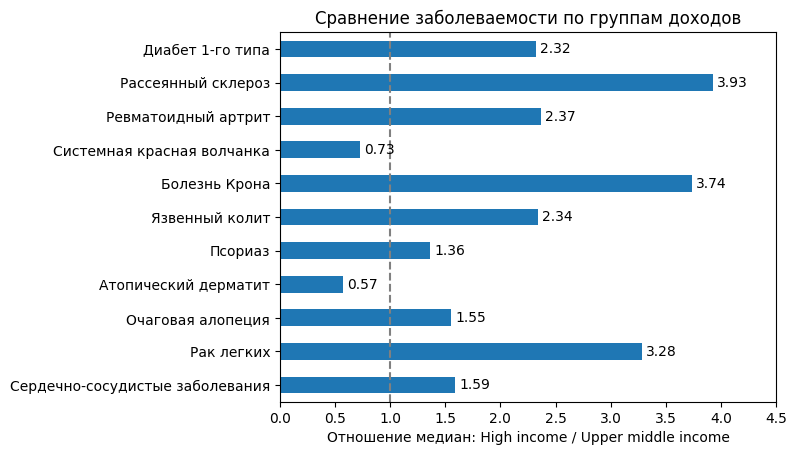

In [180]:
import matplotlib.pyplot as plt

ax = income_comparison['median_ratio'].rename(index=disease_labels).plot.barh()
plt.gca().invert_yaxis()
plt.axvline(x=1, color='gray', linestyle='--')
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)
plt.title('Сравнение заболеваемости по группам доходов')
plt.xlabel('Отношение медиан: High income / Upper middle income')
plt.xlim(0, 4.5)
plt.savefig('../visualizations/income_median_ratio.png',
            dpi=300, bbox_inches='tight')
plt.show()

## Корреляции заболеваемости с долей населения старше 65 лет

In [181]:
age_corr = {}
for i in incidence_cols_t:
    age_corr[i] = disease_analysis_demo_final[['population_65plus_pct_2023', i]].corr().loc['population_65plus_pct_2023', i].round(2)
print(age_corr)
    

{'t1d_incidence_2024_per100k': np.float64(0.27), 'ms_incidence_2023_per100k': np.float64(0.59), 'ra_incidence_2023_per100k': np.float64(0.65), 'uc_incidence_2023_per100k': np.float64(0.68), 'ps_incidence_2023_per100k': np.float64(0.85), 'sle_incidence_estimate_per100k': np.float64(0.14), 'cd_incidence_2023_per100k': np.float64(0.57), 'ad_incidence_2023_per100k': np.float64(-0.43), 'aa_incidence_2023_per100k': np.float64(0.76), 'lung_incidence_2023_per100k': np.float64(0.87), 'cvd_incidence_2023_per100k': np.float64(0.89)}


In [182]:
age_corr_series = pd.Series(age_corr)
age_corr_series

t1d_incidence_2024_per100k        0.27
ms_incidence_2023_per100k         0.59
ra_incidence_2023_per100k         0.65
uc_incidence_2023_per100k         0.68
ps_incidence_2023_per100k         0.85
sle_incidence_estimate_per100k    0.14
cd_incidence_2023_per100k         0.57
ad_incidence_2023_per100k        -0.43
aa_incidence_2023_per100k         0.76
lung_incidence_2023_per100k       0.87
cvd_incidence_2023_per100k        0.89
dtype: float64

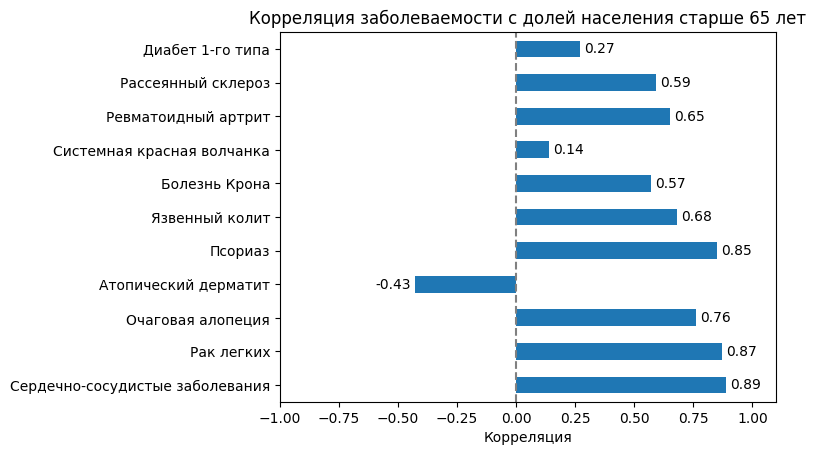

In [183]:
ax = age_corr_series.reindex(disease_order).rename(index=disease_labels).plot.barh()
plt.gca().invert_yaxis()
plt.axvline(x=0, color='gray', linestyle='--')
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)
plt.title('Корреляция заболеваемости с долей населения старше 65 лет')
plt.xlabel('Корреляция')
plt.xlim(-1, 1.1)
plt.savefig('../visualizations/age_corr_series.png',
            dpi=300, bbox_inches='tight')
plt.show()

## Тепловая карта корреляций

In [184]:
corr_matrix = disease_analysis_demo_final.corr(numeric_only=True)
corr_matrix.shape

(14, 14)

In [185]:
corr_selected = corr_matrix.loc[incidence_cols_demo,['gdp_per_capita_ppp_2024','life_expectancy_2023','population_65plus_pct_2023']]

corr_selected.shape

(11, 3)

In [186]:
corr_selected = corr_selected.reindex(disease_order)
corr_selected.round(2)

,gdp_per_capita_ppp_2024,life_expectancy_2023,population_65plus_pct_2023
t1d_incidence_2024_per100k,0.44,0.41,0.27
ms_incidence_2023_per100k,0.68,0.59,0.59
ra_incidence_2023_per100k,0.64,0.65,0.65
sle_incidence_estimate_per100k,0.02,0.07,0.14
cd_incidence_2023_per100k,0.56,0.50,0.57
uc_incidence_2023_per100k,0.63,0.60,0.68
ps_incidence_2023_per100k,0.75,0.85,0.85
ad_incidence_2023_per100k,-0.26,-0.16,-0.43
aa_incidence_2023_per100k,0.66,0.69,0.76
lung_incidence_2023_per100k,0.60,0.62,0.87


In [187]:
corr_labels = {
    'gdp_per_capita_ppp_2024': 'ВВП на душу (ППС)',
    'life_expectancy_2023': 'Продолжительность жизни',
    'population_65plus_pct_2023': 'Население 65+, %'
}

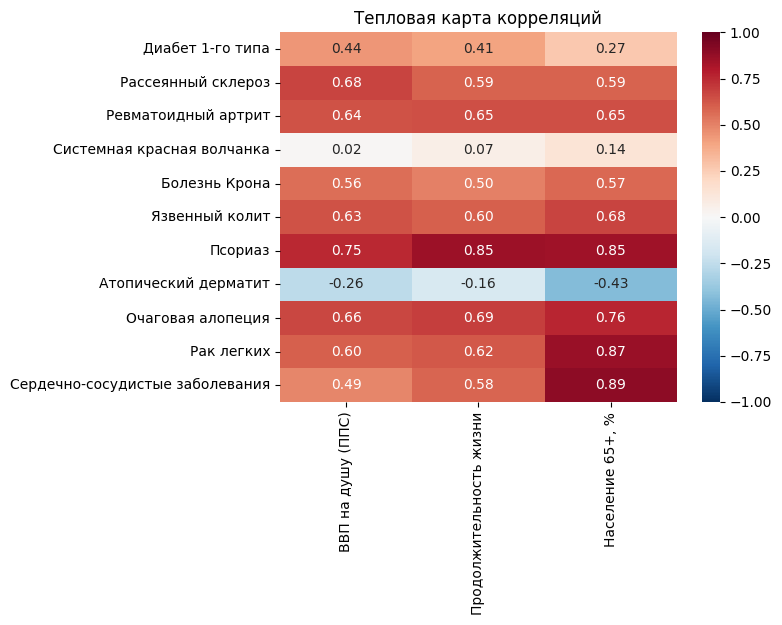

In [188]:
import seaborn as sns

sns.heatmap(
    corr_selected.rename(index=disease_labels, columns=corr_labels),
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    center=0
)
plt.title('Тепловая карта корреляций')
plt.savefig('../visualizations/corr_selected.png',
            dpi=300, bbox_inches='tight')

### Влияние возрастной структуры населения
Для проверки возможного влияния демографического фактора в анализ были добавлены два показателя: ожидаемая продолжительность жизни и доля населения старше 65 лет.
Корреляционный анализ показал, что для части заболеваний связь с долей населения 65+ действительно присутствует. Наиболее высокая положительная корреляция наблюдается для сердечно-сосудистых заболеваний (0.89), рака лёгких (0.87) и псориаза (0.85). Для рассеянного склероза, ревматоидного артрита, болезни Крона и язвенного колита связь умеренная. Для системной красной волчанки корреляция слабая (0.14), а для атопического дерматита — отрицательная (-0.43).
Это означает, что возрастная структура населения влияет на показатели заболеваемости, однако не может полностью объяснить различия между группами стран по уровню дохода. В частности, для ряда аутоиммунных заболеваний различия медианных значений между High income и Upper middle income остаются значительно более выраженными, чем можно было бы ожидать только за счёт старения населения.

## Тепловая карта по странам двух категорий доходов (High income / Upper middle income)

In [189]:
disease_order = [
    't1d_incidence_2024_per100k',
    'ms_incidence_2023_per100k',
    'ra_incidence_2023_per100k',
    'sle_incidence_estimate_per100k',
    'cd_incidence_2023_per100k',
    'uc_incidence_2023_per100k',
    'ps_incidence_2023_per100k',
    'ad_incidence_2023_per100k',
    'aa_incidence_2023_per100k',
    'lung_incidence_2023_per100k',
    'cvd_incidence_2023_per100k']

disease_labels = {
    't1d_incidence_2024_per100k': 'Диабет 1-го типа',
    'ms_incidence_2023_per100k': 'Рассеянный склероз',
    'ra_incidence_2023_per100k': 'Ревматоидный артрит',
    'sle_incidence_estimate_per100k': 'Системная красная волчанка',
    'cd_incidence_2023_per100k': 'Болезнь Крона',
    'uc_incidence_2023_per100k': 'Язвенный колит',
    'ps_incidence_2023_per100k': 'Псориаз',
    'ad_incidence_2023_per100k': 'Атопический дерматит',
    'aa_incidence_2023_per100k': 'Очаговая алопеция',
    'lung_incidence_2023_per100k': 'Рак легких',
    'cvd_incidence_2023_per100k': 'Сердечно-сосудистые заболевания'}

In [190]:
immune_cols = disease_order[:-2]

heatmap_data = disease_analysis_demo_final.loc[disease_analysis_demo_final['incomeLevel.value']
        .isin(['High income', 'Upper middle income']),['country', 'incomeLevel.value'] + immune_cols].copy()

heatmap_data.shape

(145, 11)

In [191]:
heatmap_matrix = heatmap_data.set_index('country')[immune_cols]
heatmap_matrix = heatmap_matrix.rename(columns=disease_labels)

heatmap_matrix.head(10)

,Диабет 1-го типа,Рассеянный склероз,Ревматоидный артрит,Системная красная волчанка,Болезнь Крона,Язвенный колит,Псориаз,Атопический дерматит,Очаговая алопеция
country,,,,,,,,,
Aruba,4.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albania,7.57,2.270127,10.689150,13.74,2.464479,4.744865,65.274385,134.175435,102.393872
Andorra,NaN,3.785033,11.453336,NaN,5.090364,8.507483,72.518378,206.746638,112.297999
United Arab Emirates,37.39,1.112269,6.277666,8.51,1.255235,3.896810,68.188972,589.517607,67.533001
Argentina,11.82,0.909896,12.882979,1.80,1.200889,4.366297,56.499195,219.483632,119.936903
Armenia,7.36,0.853303,6.464687,1.18,1.667843,4.449111,64.158548,204.771197,103.972278
American Samoa,NaN,0.102933,4.362309,NaN,0.231609,0.616298,50.517320,629.271880,70.657142
Antigua and Barbuda,4.79,0.611602,10.937320,7.88,0.887100,2.426134,55.496283,380.297290,66.501049
Australia,15.31,2.182457,30.142815,1.34,12.166010,10.543556,63.965624,226.101257,119.433039


In [192]:
heatmap_colors = heatmap_matrix.rank(pct=True)

heatmap_colors.head(10)

,Диабет 1-го типа,Рассеянный склероз,Ревматоидный артрит,Системная красная волчанка,Болезнь Крона,Язвенный колит,Псориаз,Атопический дерматит,Очаговая алопеция
country,,,,,,,,,
Aruba,0.319672,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albania,0.491803,0.781250,0.484375,0.948276,0.703125,0.687500,0.625000,0.039062,0.625000
Andorra,NaN,0.898438,0.546875,NaN,0.804688,0.851562,0.968750,0.218750,0.890625
United Arab Emirates,0.983607,0.570312,0.265625,0.862069,0.601562,0.593750,0.789062,0.804688,0.351562
Argentina,0.688525,0.539062,0.593750,0.094828,0.578125,0.664062,0.460938,0.304688,0.937500
Armenia,0.467213,0.531250,0.281250,0.034483,0.671875,0.679688,0.578125,0.203125,0.695312
American Samoa,NaN,0.062500,0.117188,NaN,0.148438,0.156250,0.273438,0.851562,0.398438
Antigua and Barbuda,0.360656,0.445312,0.500000,0.788793,0.398438,0.390625,0.406250,0.640625,0.328125
Australia,0.786885,0.773438,0.929688,0.060345,0.976562,0.882812,0.570312,0.359375,0.929688


In [193]:
heatmap_matrix.notna().sum(axis=1).value_counts().sort_index()

0     10
1      7
7     12
8      1
9    115
Name: count, dtype: int64

In [194]:
heatmap_colors_filtered = heatmap_colors.loc[heatmap_matrix.notna().sum(axis=1) >= 7]

heatmap_colors_filtered.shape

(128, 9)

In [195]:
country_mean = heatmap_colors_filtered.mean(axis=1)

heatmap_colors_filtered = heatmap_colors_filtered.loc[country_mean.sort_values(ascending=False).index]

In [196]:
country_mean.sort_values(ascending=False).head(20).round(3)

country
Sweden            0.790
United States     0.789
Netherlands       0.785
Norway            0.779
Canada            0.764
Denmark           0.758
Finland           0.758
Greenland         0.753
Monaco            0.751
San Marino        0.750
United Kingdom    0.742
Andorra           0.740
Ireland           0.733
Slovenia          0.718
Iceland           0.709
Switzerland       0.708
New Zealand       0.704
Czechia           0.703
Austria           0.701
Australia         0.697
dtype: float64

### Географическое распределение аутоиммунных и иммунноопосредованных заболеваний

Для изучения различий между отдельными странами построена тепловая карта заболеваемости по девяти аутоиммунным и иммуноопосредованным заболеваниям.

**Подготовка данных:**

- Первоначально отобраны 145 стран и территорий из двух категорий Всемирного банка: *High income* и *Upper middle income*.
- Проверена полнота данных. В окончательную визуализацию включены 128 стран и территорий, для которых доступны показатели минимум по 7 из 9 заболеваний.
- Для каждого заболевания независимо рассчитаны процентильные ранги стран. Это позволяет сравнивать относительные позиции стран, несмотря на различия в абсолютных масштабах заболеваемости.
- Страны отсортированы по среднему процентильному рангу по доступным заболеваниям.

**Как читать карту:**

Чем темнее зелёный цвет, тем выше оценочный показатель заболеваемости в стране относительно других стран выборки по данному заболеванию.

Белые клетки обозначают отсутствие данных.

Цвета отражают относительные позиции стран, а не абсолютное число новых случаев на 100 тысяч населения.

Полученная визуализация предназначена для выявления географических закономерностей и стран с необычными сочетаниями показателей. Она не позволяет самостоятельно установить причины наблюдаемых различий.

In [197]:
income_groups = heatmap_data.set_index('country')['incomeLevel.value'].reindex(
    heatmap_colors_filtered.index)
income_groups.value_counts(dropna=False)

incomeLevel.value
High income            70
Upper middle income    58
Name: count, dtype: int64

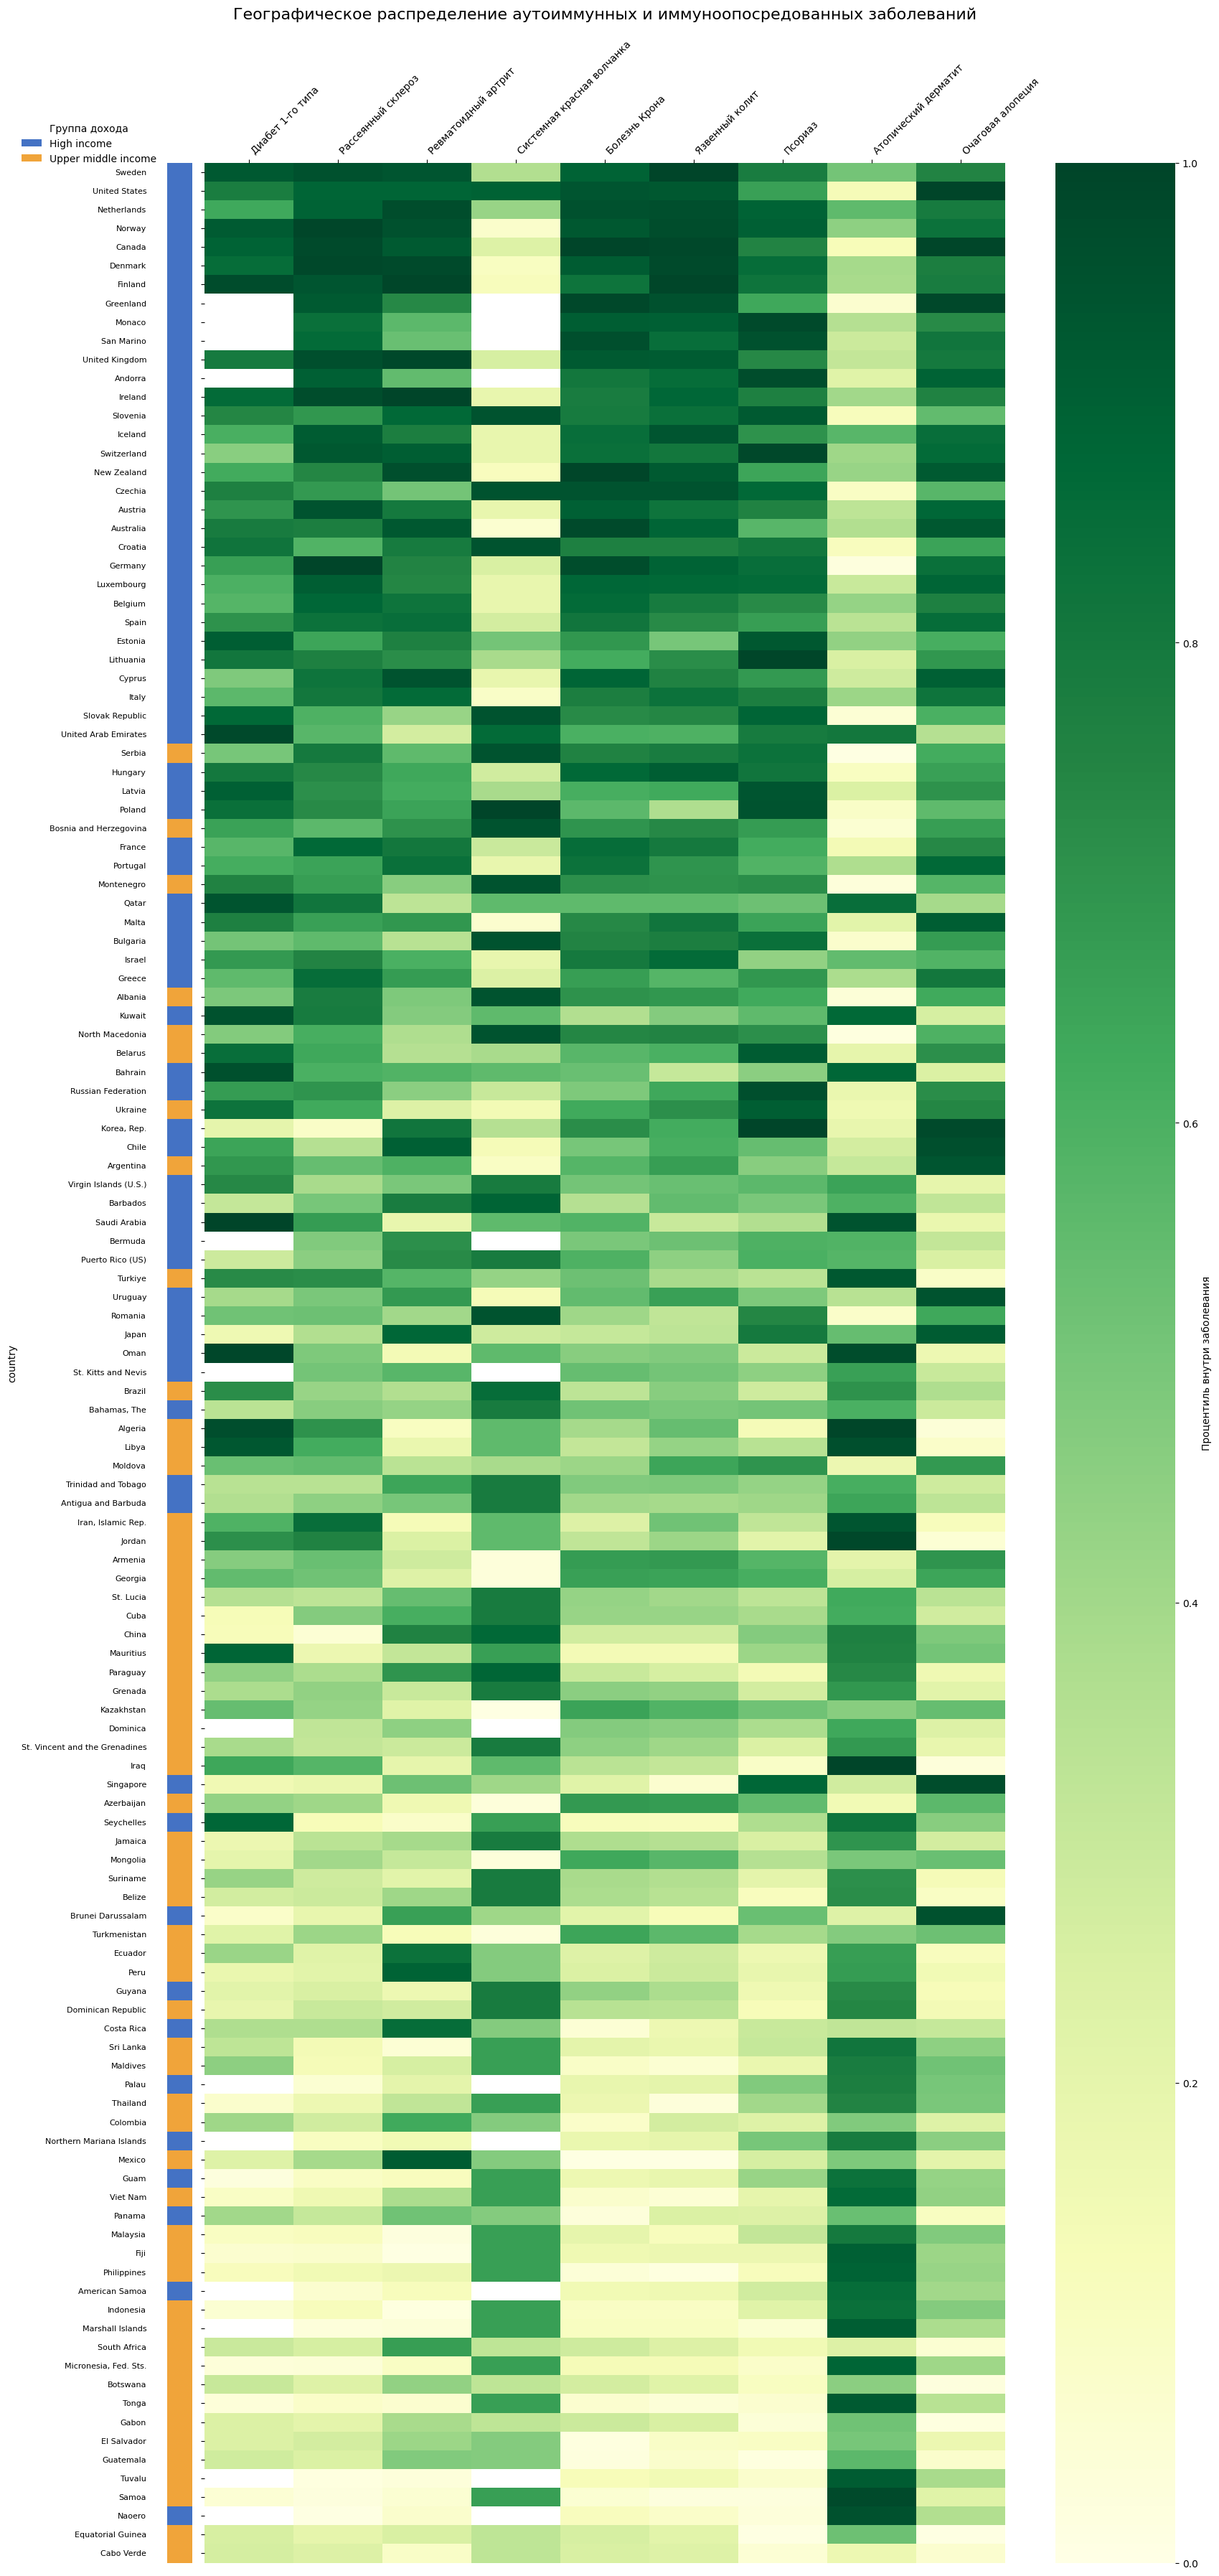

In [198]:
plt.figure(figsize=(17, 36))

ax = sns.heatmap(
    heatmap_colors_filtered,
    cmap='YlGn',
    vmin=0,
    vmax=1,
    yticklabels=True,
    cbar_kws={'label': 'Процентиль внутри заболевания'}
)
from matplotlib.patches import Rectangle

income_colors = {'High income': '#4472C4','Upper middle income': '#F0A43A'}

for i, group in enumerate(income_groups):
    ax.add_patch(Rectangle(
        (-0.42, i), 0.28, 1,
        facecolor=income_colors[group],
        edgecolor='none',
        clip_on=False))

ax.tick_params(axis='y', pad=55)

ax.xaxis.tick_top()

plt.xticks(rotation=45, ha='left', fontsize=10)
plt.yticks(fontsize=8)
plt.title(
    'Географическое распределение аутоиммунных и иммуноопосредованных заболеваний',
    fontsize=16,
    pad=20)
from matplotlib.patches import Patch

legend_handles = [
    Patch(facecolor=income_colors['High income'], label='High income'),
    Patch(facecolor=income_colors['Upper middle income'], label='Upper middle income')
]

ax.legend(
    handles=legend_handles,
    title='Группа дохода',
    loc='upper left',
    bbox_to_anchor=(-0.24, 1.02),
    frameon=False)
plt.tight_layout()
plt.savefig(
    '../visualizations/heatmap_countries_128.png',
    dpi=300,
    bbox_inches='tight')
plt.show()

## Атопический дерматит возраст-стандартизированная оценка

In [199]:
ad_age_standardized = pd.read_csv('../data/raw/ad_incidence_2023_age_standardized/ad_incidence_2023_age_standardized.csv')

In [200]:
ad_age_standardized.head(3)

,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,6,Incidence,7,Democratic People's Republic of Korea,3,Both,27,Age-standardized,977,Atopic dermatitis,3,Rate,2023,716.973146,767.841951,662.708028
1,1,All Population,6,Incidence,44,Bosnia and Herzegovina,3,Both,27,Age-standardized,977,Atopic dermatitis,3,Rate,2023,140.855207,146.680731,134.176142
2,1,All Population,6,Incidence,8,Taiwan,3,Both,27,Age-standardized,977,Atopic dermatitis,3,Rate,2023,714.901447,765.680324,660.765862


In [201]:
ad_age_standardized_selected = ad_age_standardized[['location_id','location_name','val','upper','lower']]
ad_age_standardized_selected = ad_age_standardized_selected.round(2).rename(columns={'location_name':'country','val':'ad_age_standardized_2023'})
ad_age_standardized_selected.sort_values('ad_age_standardized_2023').head(30)

,location_id,country,ad_age_standardized_2023,upper,lower
53,53,Serbia,139.71,145.51,133.03
174,55,Slovenia,140.19,146.04,133.52
198,51,Poland,140.22,144.53,135.14
164,50,Montenegro,140.35,146.14,133.68
4,45,Bulgaria,140.47,146.31,133.79
128,49,North Macedonia,140.61,146.43,133.93
29,47,Czechia,140.77,146.62,134.07
199,52,Romania,140.79,146.65,134.09
1,44,Bosnia and Herzegovina,140.86,146.68,134.18
62,43,Albania,140.91,146.70,134.26


In [202]:
ad_age_standardized[
    ['age_name', 'measure_name', 'metric_name', 'cause_name', 'year']
].drop_duplicates()

,age_name,measure_name,metric_name,cause_name,year
0,Age-standardized,Incidence,Rate,Atopic dermatitis,2023


In [203]:
disease_analysis_end_demo

,code,country,incomeLevel.value,gdp_per_capita_ppp_2024,t1d_incidence_2024_per100k,ms_incidence_2023_per100k,ra_incidence_2023_per100k,uc_incidence_2023_per100k,ps_incidence_2023_per100k,sle_incidence_estimate_per100k,cd_incidence_2023_per100k,ad_incidence_2023_per100k,aa_incidence_2023_per100k,lung_incidence_2023_per100k,cvd_incidence_2023_per100k,life_expectancy_2023,population_65plus_pct_2023
0,ABW,Aruba,High income,45428.00,4.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,76.35,16.37
1,AFG,Afghanistan,Low income,1964.45,3.84,0.961012,2.959350,1.401695,25.514249,7.18,0.538645,1316.961289,51.164303,1.948582,318.807627,66.04,2.38
2,AGO,Angola,Lower middle income,8752.80,4.24,0.195506,4.261433,0.761775,29.707758,5.14,0.452931,311.321634,49.618271,3.332687,419.853128,64.62,2.81
3,ALB,Albania,Upper middle income,21640.98,7.57,2.270127,10.689150,4.744865,65.274385,13.74,2.464479,134.175435,102.393872,43.977450,1052.660599,79.60,16.30
4,AND,Andorra,High income,66232.74,NaN,3.785033,11.453336,8.507483,72.518378,NaN,5.090364,206.746638,112.297999,68.797735,804.261440,84.04,15.42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,WSM,Samoa,Upper middle income,7687.23,0.30,0.093765,3.533412,0.418786,38.404500,7.40,0.164025,862.178496,64.725027,7.031349,439.315320,71.70,5.71
212,XKX,Kosovo,Upper middle income,15716.29,8.32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78.03,9.64
214,ZAF,South Africa,Upper middle income,13597.65,4.16,0.349547,15.678724,0.947033,46.011335,5.14,0.587985,208.359260,59.838191,17.182028,439.632442,66.14,6.52
215,ZMB,Zambia,Lower middle income,3708.07,4.42,0.207415,3.666734,0.787877,30.194575,5.14,0.480647,325.602479,49.327270,1.419462,384.232554,66.35,1.90
